# Structural Effects on Neural Dynamics

**Author:** Xiaoge Bao  
**Affiliation:** Institut d’Investigacions Biomèdiques August Pi i Sunyer (IDIBAPS), Barcelona, Spain  
**Contact:** [XBAO@recerca.clinic.cat](mailto:XBAO@recerca.clinic.cat)  
**Date:** November 2026

**Main Question:** How does circuit structure transform a perturbation into delayed, persistent, suppressed, oscillatory, or amplified activity in linear models?

**Dependencies:** Python 3.10+, NumPy, SciPy, Matplotlib, NetworkX and ipywidgets. 
| Stage | Structure | Central question | Computational phenomena |
|---|---|---|---|
| 1 | One unit with self-feedback | How do local decay and self-feedback shape responses to different inputs? | Filtering, gain, relaxation, and integration |
| 2 | Feedforward chain with signed couplings | How do response strength and timescale accumulate along a single path? | Sequential activity, finite-horizon memory, suppression, and disinhibition |
| 3 | Feedforward networks with parallel pathways | How do perturbations propagating along different feedforward paths combine? | Feedforward excitation and inhibition, amplification, cancellation, and selective transmission |
| 4 | Feedback loops with signed couplings | How does repeated circulation change response strength, timing, and stability? | Recurrent amplification, slowing, feedback inhibition, mutual inhibition, and damped oscillations |
| 5 | Recurrent excitatory–inhibitory circuits | How do excitatory and inhibitory feedback jointly shape stability and amplification? | Inhibitory stabilization, paradoxical responses, and balanced amplification |

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lfilter
from IPython.display import display
from scipy.linalg import expm, solve_continuous_lyapunov
from scipy.integrate import solve_ivp
from scipy.sparse.linalg import expm_multiply
from scipy.signal import correlate
from scipy.integrate import trapezoid
from matplotlib.lines import Line2D
from matplotlib.patches import Circle, FancyArrowPatch
from scipy.special import gammaln, gammaincc
try:
    import ipywidgets as widgets
except ImportError:
    widgets = None

### 1. One unit with self-feedback

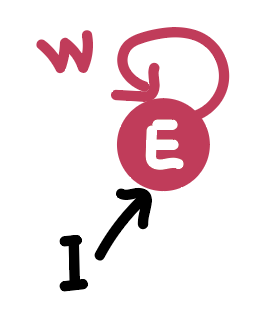

Consider
$$
\dot{x}=-\beta x+I(t),\qquad \beta>0,\qquad x(0^-)=0.
$$
The fundamental strength gain and timescale are
$$
R=\frac{1}{\beta},
\qquad
\tau=\frac{1}{\beta}.
$$
For a unit with intrinsic time constant $\tau_0$ and dimensionless self-feedback $w$, $\beta=(1-w)/\tau_0$. Increasing positive feedback therefore increases both gain and timescale, provided $w<1$ for stability.

**Impulse input:** $I(t)=A\delta(t)$.
$$
x(t)=A e^{-t/\tau},
\qquad
\int_0^\infty x(t)\,dt=AR.
$$
The peak is $A$; the integrated response is $AR$, and the decay time when reaching $\frac{A}{e}$ is $\tau$.

**Step input:** $I(t)=A\,\mathbf{1}_{t\ge0}$.
$$
x(t)=AR\left(1-e^{-t/\tau}\right),
\qquad
x_{\mathrm{ss}}=AR.
$$
The steady response is $AR$, approached $(1-\frac{1}{e})A$ with time constant $\tau$.

**Square input:** $I(t)=A\,\mathbf{1}_{0\le t\le t_s}$.
$$
x_{\mathrm{peak}}=AR\left(1-e^{-t_s/\tau}\right),
\qquad
\int_0^\infty x(t)\,dt=ARt_s.
$$
The response decays with time constant $\tau$. 

**White-noise input:** $I(t)=\sqrt{Q}\,\xi(t)$, where
$\langle\xi(t)\xi(s)\rangle=\delta(t-s)$.
The stationary autocovariance with time-lag $\Delta$ is
$$
C(\Delta)=\frac{QR}{2}e^{-|\Delta|/\tau}.
$$
Thus,
$$
\operatorname{Var}(x)=\frac{QR}{2},
\qquad
\int_{-\infty}^{\infty}C(\Delta)\,d\Delta=QR^2,
$$
and the correlation decay timescale is $\tau$.

The same $R$ and $\tau$ govern all four cases.

In [13]:
# Appearance
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 15,
    "axes.titlesize": 20,
    "axes.labelsize": 17,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 13,
    "figure.titlesize": 22,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

BLUE, RED, GOLD = "#2864ad", "#c34048", "#bb8b18"

# Fixed time settings
T_MAX = 30.0
DT = 0.01
NOISE_RECORD = 8000.0

# Fixed y-axis limits across all parameter settings.
# Current sliders give R_max = 2 / (1 - 0.9) = 20.
Y_LIMITS = [
    (-0.05, 1.10),  # Impulse
    (-1.0, 22.0),   # Step
    (-1.0, 22.0),   # Square
    (-15.0, 15.0),  # White noise
    (-2.0, 12.0),   # Autocovariance
]


def slider(value, lo, hi, step=0.1):
    if widgets is None:
        return value

    return widgets.FloatSlider(
        value=value,
        min=lo,
        max=hi,
        step=step,
        continuous_update=False,
        style={"description_width": "initial"},
        layout=widgets.Layout(width="450px"),
    )


def interact_demo(fn, controls):
    if widgets is None:
        print("Widgets unavailable: change the arguments in local_demo().")
        return

    display(widgets.interactive(fn, **controls))


def local_demo(tau0=1.0, feedback=0.5, duration=2.0, seed=1):
    """
    dx/dt = -beta*x + u(t), beta = (1-feedback)/tau0.

    Impulse: unit area.
    Step/square: unit height.
    White noise: unit intensity.

    Deterministic responses start from zero.
    The noise-driven response starts in its stationary distribution.
    """
    beta = (1.0 - feedback) / tau0

    if beta <= 0:
        print("Choose feedback < 1 for a stable system.")
        return

    R = tau = 1.0 / beta

    # ------------------------------------------------------------
    # Exact deterministic responses
    # ------------------------------------------------------------
    t = np.linspace(0, T_MAX, 2001)

    impulse = np.exp(-t / tau)
    step = R * (-np.expm1(-t / tau))

    peak = R * (-np.expm1(-duration / tau))

    square = np.empty_like(t)
    during = t <= duration

    square[during] = R * (-np.expm1(-t[during] / tau))
    square[~during] = peak * np.exp(
        -(t[~during] - duration) / tau
    )

    # ------------------------------------------------------------
    # Exact stationary Ornstein–Uhlenbeck simulation
    # Fixed sampling interval and recording length
    # ------------------------------------------------------------
    rng = np.random.default_rng(seed)
    n = int(round(NOISE_RECORD / DT)) + 1

    a = np.exp(-DT / tau)
    variance = R / 2

    innovation_sd = np.sqrt(
        variance * (-np.expm1(-2 * DT / tau))
    )

    noise_response = np.empty(n)
    noise_response[0] = rng.normal(scale=np.sqrt(variance))
    innovations = rng.standard_normal(n - 1)

    noise_response[1:], _ = lfilter(
        [innovation_sd],
        [1.0, -a],
        innovations,
        zi=[a * noise_response[0]],
    )

    # Empirical stationary autocovariance
    centered = noise_response - noise_response.mean()
    nfft = 1 << (2 * n - 1).bit_length()
    ft = np.fft.rfft(centered, n=nfft)

    max_lag = int(round(T_MAX / DT))

    covariance = np.fft.irfft(
        ft * np.conj(ft), n=nfft
    )[:max_lag + 1]

    covariance /= n - np.arange(max_lag + 1)

    lag = np.arange(max_lag + 1) * DT
    theory_cov = variance * np.exp(-lag / tau)

    # ------------------------------------------------------------
    # Five panels
    # ------------------------------------------------------------
    fig = plt.figure(figsize=(19, 10), layout="constrained")
    gs = fig.add_gridspec(2, 6)

    ax = [
        fig.add_subplot(gs[0, 0:2]),
        fig.add_subplot(gs[0, 2:4]),
        fig.add_subplot(gs[0, 4:6]),
        fig.add_subplot(gs[1, 0:3]),
        fig.add_subplot(gs[1, 3:6]),
    ]

    fig.suptitle(
        rf"$\dot x=-\beta x+u(t)$"
        rf"     $\beta={beta:.3g}$"
        rf"     $R={R:.3g}$"
        rf"     $\tau={tau:.3g}$"
    )

    # 1. Impulse
    ax[0].plot(t, impulse, color=BLUE, lw=2.5)

    ax[0].fill_between(
        t,
        impulse,
        color=BLUE,
        alpha=0.15,
        label=rf"$\int_0^\infty x(t)\,dt=R={R:.3g}$",
    )

    if tau <= T_MAX:
        ax[0].axvline(
            tau, color=GOLD, ls="--", label=r"$t=\tau$"
        )
        ax[0].scatter(
            [tau], [1 / np.e],
            color=GOLD, s=65, zorder=3,
        )

    ax[0].set(
        title="Impulse",
        xlabel="Time",
        ylabel="Response",
    )

    # 2. Step
    ax[1].plot(t, step, color=BLUE, lw=2.5)

    ax[1].axhline(
        R, color=RED, ls="--", label=rf"$R={R:.3g}$"
    )

    if tau <= T_MAX:
        ax[1].axvline(
            tau, color=GOLD, ls="--", label=r"$t=\tau$"
        )
        ax[1].scatter(
            [tau], [R * (1 - 1 / np.e)],
            color=GOLD, s=65, zorder=3,
        )

    ax[1].set(
        title="Step",
        xlabel="Time",
        ylabel="Response",
    )

    # 3. Square
    ax[2].plot(t, square, color=BLUE, lw=2.5)

    ax[2].axvspan(
        0,
        min(duration, T_MAX),
        color=GOLD,
        alpha=0.12,
        label="Input on",
    )

    ax[2].axhline(
        R, color=RED, ls="--", label=rf"$R={R:.3g}$"
    )

    if duration <= T_MAX:
        ax[2].scatter(
            [duration], [peak],
            color=RED, s=65, zorder=3,
        )

    if duration + tau <= T_MAX:
        ax[2].axvline(
            duration + tau,
            color=GOLD,
            ls=":",
            label=r"$t=t_s+\tau$",
        )
        ax[2].scatter(
            [duration + tau], [peak / np.e],
            color=GOLD, s=65, zorder=3,
        )

    ax[2].set(
        title="Square",
        xlabel="Time",
        ylabel="Response",
    )

    # 4. White-noise-driven response
    n_visible = max_lag + 1
    tn = np.arange(n_visible) * DT

    ax[3].plot(
        tn,
        noise_response[:n_visible],
        color=BLUE,
        lw=1.1,
    )

    sd = np.sqrt(variance)

    ax[3].axhline(
        sd,
        color=RED,
        ls="--",
        label=rf"$\mathrm{{SD}}=\sqrt{{R/2}}={sd:.3g}$",
    )
    ax[3].axhline(-sd, color=RED, ls="--")
    ax[3].axhline(0, color="gray", lw=0.7)

    ax[3].set(
        title="White noise",
        xlabel="Time",
        ylabel="Response",
    )

    # 5. Autocovariance
    ax[4].plot(
        lag,
        theory_cov,
        color=BLUE,
        lw=2.5,
        label=r"$C(\Delta)=(R/2)e^{-|\Delta|/\tau}$",
    )

    ax[4].plot(
        lag,
        covariance,
        color=RED,
        lw=1.7,
        alpha=0.8,
        label="Sample estimate",
    )

    if tau <= T_MAX:
        ax[4].axvline(
            tau,
            color=GOLD,
            ls="--",
            label=r"$\Delta=\tau$",
        )
        ax[4].scatter(
            [tau], [variance / np.e],
            color=GOLD, s=65, zorder=3,
        )

    ax[4].scatter(
        [0], [variance],
        color=BLUE, s=65, zorder=3,
    )

    ax[4].set(
        title="Autocovariance",
        xlabel="Lag",
        ylabel="Autocovariance",
    )

    # Fixed x- and y-axis limits for every parameter setting
    for axis, ylim in zip(ax, Y_LIMITS):
        axis.set_xlim(0, T_MAX)
        axis.set_ylim(*ylim)
        axis.grid(alpha=0.15)
        axis.legend(loc="upper right", framealpha=0.9)

    plt.show()

# Interactive controls
if widgets is not None:
    interact_demo(
        local_demo,
        dict(
            tau0=slider(1.0, 0.5, 2.0, 0.1),
            feedback=slider(0.5, -1.0, 0.9, 0.05),
            duration=slider(2.0, 0.2, 10.0, 0.2),
            seed=widgets.IntSlider(
                value=1,
                min=0,
                max=20,
                description="Noise seed",
                continuous_update=False,
                layout=widgets.Layout(width="450px"),
            ),
        ),
    )

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='tau0', layout=Layout(width=…

**Question:** Here we assume \(w < 1\) for stability. What will happen when \(w = 1\)?

<details>
<summary>Interpretation / discussion</summary>

**Answer:** It becomes a **line attractor**!

*   **Phenomenon:** Persistence of activity and neural integration.
*   **Computational question:** Can effective memory outlast local decay?
*   **Literature anchor:** [Seung (1996), *How the brain keeps the eyes still*](https://doi.org/10.1073/pnas.93.23.13339).

</details>

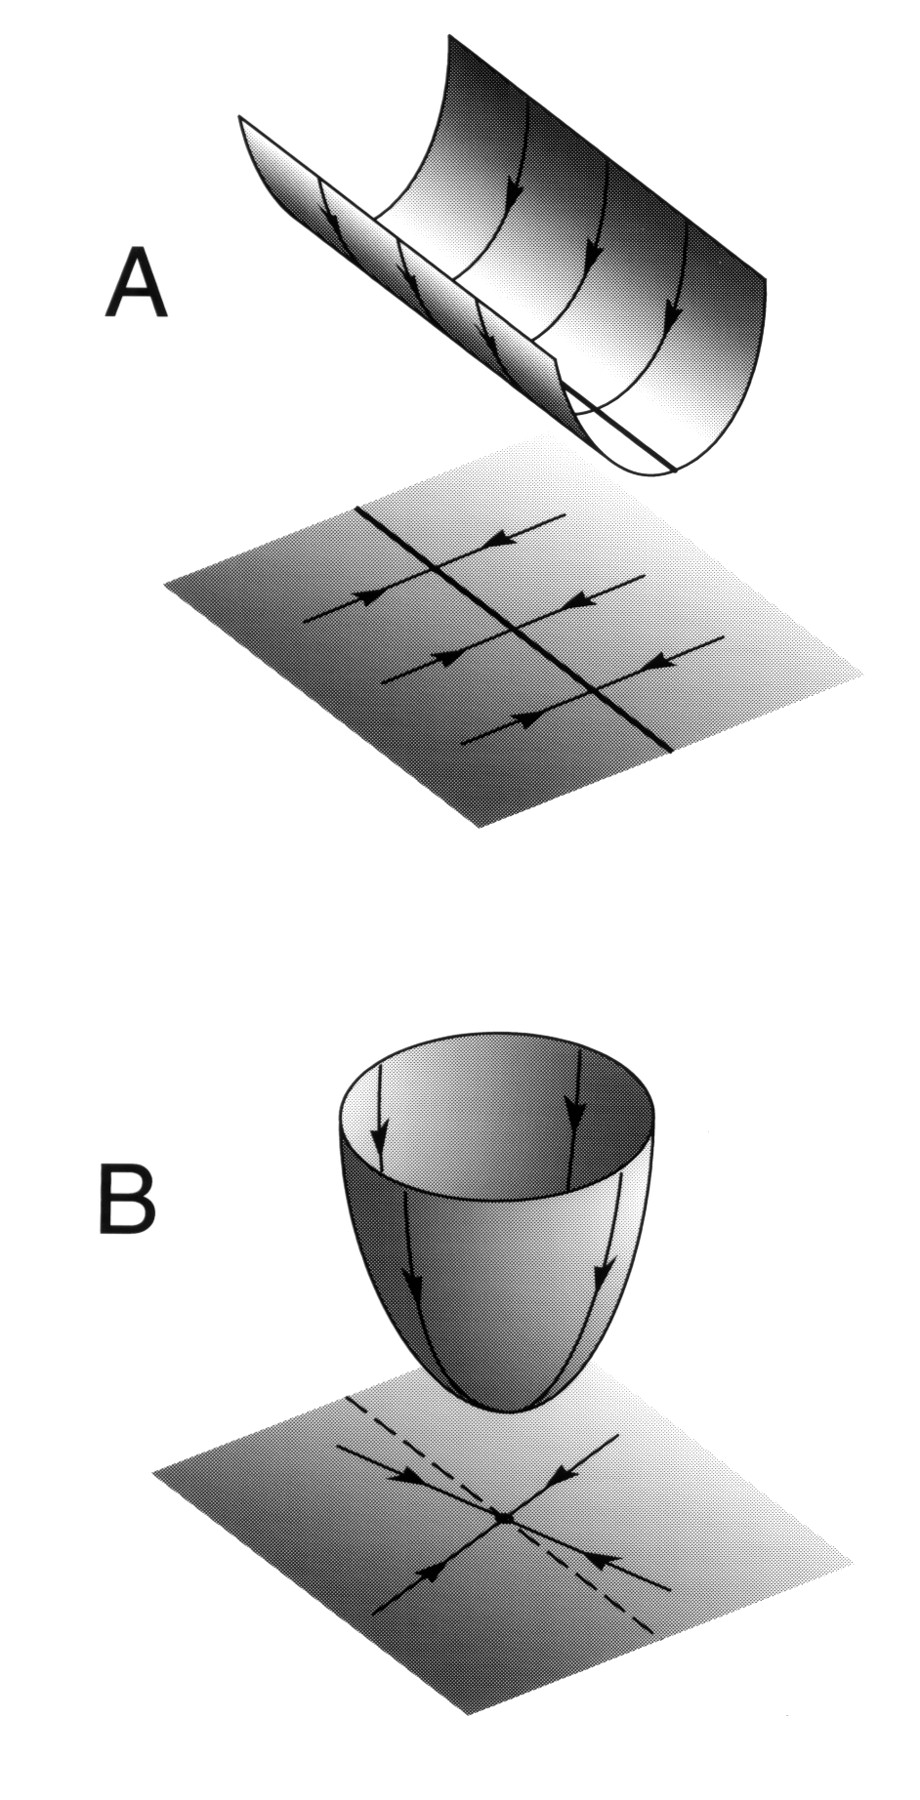

Adapted from Seung (1996), Fig. 1, *How the brain keeps the eyes still*

### 2. Feedforward chain

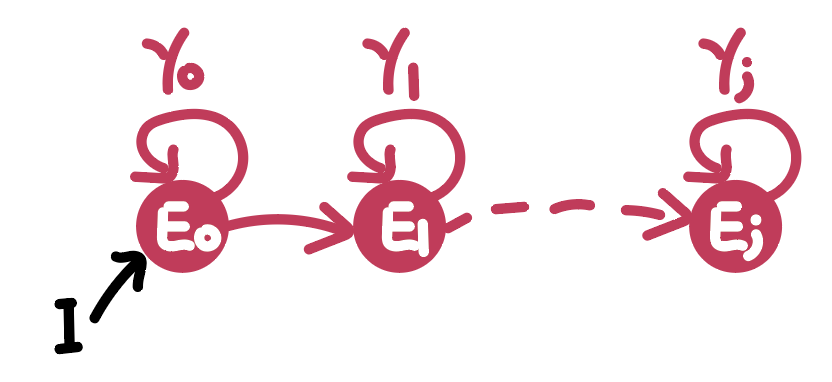

Consider a chain driven by an input $I(t)$ at node 0:
$$
\dot{x}_0=-\frac{x_0}{\gamma_0}+I(t),
\qquad
\dot{x}_j=-\frac{x_j}{\gamma_j}+a_jx_{j-1},
\quad j\ge1.
$$
Here $\gamma_j>0$ is the local time constant and $a_j>0$ is the feedforward coupling. 

The **iterative laws** for strength gain and timescales are
$$
R_0=\gamma_0,
\qquad
R_j=a_j\gamma_jR_{j-1},
$$
$$
\tau_0=\gamma_0,
\qquad
\tau_j=\tau_{j-1}+\gamma_j.
$$
Thus,
$$
R_j=
\left(\prod_{k=1}^{j}a_k\right)
\left(\prod_{k=0}^{j}\gamma_k\right),
\qquad
\tau_j=\sum_{k=0}^{j}\gamma_k.
$$
Integrated strength accumulates **multiplicatively**; moment-based response time accumulates **additively**. 

In [14]:
def chain_matrix(n=6,weight=1.,tau=1.,last_tau=1.):
    gam=np.full(n,tau); gam[-1]=last_tau
    H=-np.diag(1/gam)
    for j in range(1,n): H[j,j-1]=weight
    return H,gam

def metrics(H,b):
    lam = np.linalg.eigvals(H); alpha = np.max(lam.real)
    if alpha >= -1e-9: return None, None, lam
    R = np.linalg.solve(-H,b); M = np.linalg.solve(-H,R)
    T = np.full_like(R,np.nan)
    np.divide(M,R,out=T,where=np.abs(R)>1e-8*max(1,np.max(np.abs(R))))
    return R,T,lam

def response(H, b, kind='impulse', duration=2., tmax=12., samples=601):
    """Exact matrix-exponential time stepping; pulse switch evaluated exactly."""
    H, b = np.asarray(H, float), np.asarray(b, float)
    n = len(b); t = np.linspace(0, tmax, samples)
    if kind == 'impulse':
        P = expm(H*(t[1]-t[0])); X = np.zeros((samples,n)); X[0] = b
        for j in range(1,samples): X[j] = P@X[j-1]
        return t, X
    A = np.zeros((n+1,n+1)); A[:n,:n] = H; A[:n,n] = b
    P = expm(A*(t[1]-t[0])); y = np.r_[np.zeros(n),1.]
    X = np.zeros((samples,n))
    for j in range(1,samples):
        y = P@y; X[j] = y[:n]
    if kind == 'square':
        # A square is the difference of two shifted steps, valid even if H is singular.
        for j in np.flatnonzero(t>duration):
            X[j] -= (expm(A*(t[j]-duration))@np.r_[np.zeros(n),1.])[:n]
    return t, X

def traces(ax,t,X,labels=None):
    for i in range(X.shape[1]): ax.plot(t,X[:,i],label=labels[i] if labels else f'node {i}')
    ax.axhline(0,color='gray',lw=.6); ax.set(xlabel='Time',ylabel='Activity deviation'); ax.legend(fontsize=8)

def finish(fig):
    fig.tight_layout(); plt.show()
    
def chain_demo(n=6,weight=1.,tau=1.,last_tau=1.):
    H,gam=chain_matrix(n,weight,tau,last_tau); b=np.eye(n)[0]
    R,T,_=metrics(H,b); t,X=response(H,b,tmax=max(15,3*np.sum(gam)))
    fig,ax=plt.subplots(2,2,figsize=(11,7))
    traces(ax[0,0],t,X); ax[0,0].plot(t,X.sum(axis=1),'k--',lw=2,label='sum readout'); ax[0,0].legend(fontsize=7,ncol=2)
    ax[0,0].set_title('Sequential responses and unweighted readout')
    im=ax[0,1].imshow(X.T,aspect='auto',origin='lower',extent=[0,t[-1],-.5,n-.5],cmap='viridis')
    ax[0,1].set(xlabel='Time',ylabel='Node',title='Activity heatmap'); fig.colorbar(im,ax=ax[0,1])
    predR=np.cumprod(gam)*weight**np.arange(n); predT=np.cumsum(gam)
    ax[1,0].plot(R,'o',label='matrix solve'); ax[1,0].plot(predR,'--',label='chain product')
    ax[1,0].set(xlabel='Node',ylabel='Integrated response R'); ax[1,0].legend()
    ax[1,1].plot(T,'o',label='moment T'); ax[1,1].plot(predT,'--',label='sum of local times')
    ax[1,1].plot(t[np.argmax(X,axis=0)],'s:',label='sampled peak time')
    ax[1,1].set(xlabel='Node',ylabel='Time'); ax[1,1].legend(); finish(fig)
    print('Eigenvalues:',np.round(np.linalg.eigvals(H),3))

# interactive example
interact_demo(chain_demo,dict(n=widgets.IntSlider(value=6,min=2,max=12,continuous_update=False) if widgets else 6, weight=slider(1,.3,1.4),tau=slider(1,.5,2),last_tau=slider(1,.5,3)))


interactive(children=(IntSlider(value=6, continuous_update=False, description='n', max=12, min=2), FloatSlider…

**Question:** Can you fine-tune the parameters to find a case where the summed activity exhibits persistent activity?

<details>
<summary>Interpretation / discussion</summary>

**Answer:** Yes, when all coupling weights and intrinsic time constants are set to unity ($w = 1, \gamma = 1$).

*   **Phenomenon:** Persistence of activity without feedback loops.
*   **Computational question:** Can effective memory be generated purely from feedforward networks?
*   **Literature anchor:** [Goldman (2009), *Memory without Feedback in a Neural Network*](https://doi.org/10.1016/j.neuron.2008.12.012).

</details>

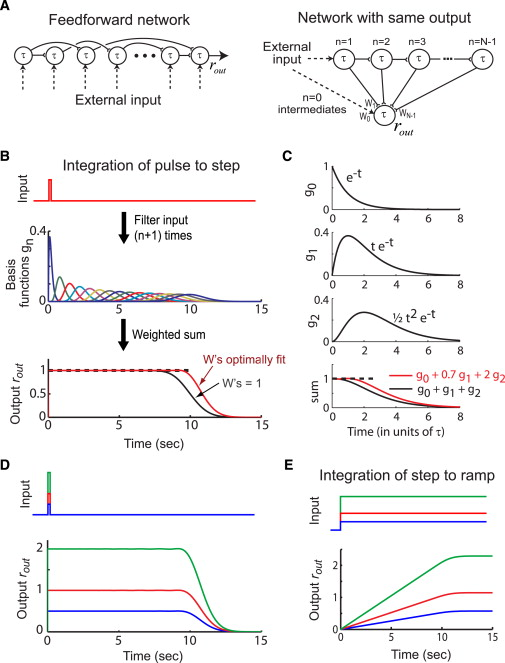

Adapted from Goldman (2009), Fig. 1, *Memory without Feedback in a Neural Network*.

Below is the comparison between input to the first node and input to all the nodes along a feedforward chain

In [4]:
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 15,
    "axes.titlesize": 19,
    "axes.labelsize": 17,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 13,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

BLUE, RED = "#2864ad", "#c34048"
T_MAX = 6.0
N_MAX = 40


def feedforward_comparison(N=20, tau_ms=100.0):
    """
    Unit impulse per targeted neuron; zero pre-input activity.

    A: input to neuron 1
       dx_1/dt = -x_1/tau + delta(t)
       dx_i/dt = (-x_i + x_{i-1})/tau

    B: input to every neuron
       dq_1/dt = -q_1/tau + delta(t)
       dq_i/dt = (-q_i + q_{i-1})/tau + delta(t)

    Exact identity: q_i(t) = sum_{j=1}^i x_j(t).
    """
    N = int(N)
    tau = tau_ms / 1000.0

    if N < 1 or tau <= 0:
        raise ValueError("Require N >= 1 and tau > 0.")

    t = np.linspace(0, T_MAX, 2401)
    z = t / tau

    # ------------------------------------------------------------
    # Exact impulse responses
    # A: x_i = exp(-z) z^(i-1) / (i-1)!
    # B: q_i = exp(-z) sum_{k=0}^{i-1} z^k/k!
    # ------------------------------------------------------------
    x = np.zeros((N, t.size))
    x[0] = np.exp(-z)

    if N > 1:
        order = np.arange(1, N)[:, None]
        x[1:, 1:] = np.exp(
            order * np.log(z[None, 1:])
            - z[None, 1:]
            - gammaln(order + 1)
        )

    neuron_indices = np.arange(1, N + 1)
    q = gammaincc(neuron_indices[:, None], z[None, :])
    sum_x = x.sum(axis=0)

    # Consistent neuron colors in both trace panels
    cmap = plt.get_cmap("viridis", N)
    colors = cmap(np.arange(N))
    norm = plt.Normalize(0.5, N + 0.5)
    ticks = np.unique(np.linspace(1, N, min(N, 6), dtype=int))

    # ------------------------------------------------------------
    # Layout: individual responses, heatmaps, readout comparison
    # ------------------------------------------------------------
    fig = plt.figure(figsize=(16, 13), layout="constrained")
    gs = fig.add_gridspec(
        3, 2,
        height_ratios=[1.1, 1.0, 0.9],
    )

    trace_axes = [
        fig.add_subplot(gs[0, 0]),
        fig.add_subplot(gs[0, 1]),
    ]
    heat_axes = [
        fig.add_subplot(gs[1, 0]),
        fig.add_subplot(gs[1, 1]),
    ]
    readout_ax = fig.add_subplot(gs[2, :])

    fig.suptitle(
        rf"Unit impulse"
        rf"     $N={N}$"
        rf"     $\tau={tau_ms:g}\,\mathrm{{ms}}$",
        fontsize=23,
    )

    # 1. Individual neuronal responses
    for axis, activity, title in zip(
        trace_axes,
        [x, q],
        ["A: input to first neuron", "B: input to every neuron"],
    ):
        for i in range(N):
            axis.plot(
                t, activity[i],
                color=colors[i],
                lw=1.8,
            )

        axis.set(
            title=title,
            xlabel="Time (s)",
            ylabel="Neuron activity",
            xlim=(0, T_MAX),
            ylim=(-0.05, 1.10),
        )
        axis.grid(alpha=0.15)

    neuron_bar = fig.colorbar(
        plt.cm.ScalarMappable(norm=norm, cmap=cmap),
        ax=trace_axes,
        fraction=0.025,
        pad=0.02,
    )
    neuron_bar.set_label("Neuron index")
    neuron_bar.set_ticks(ticks)

    # 2. Corresponding heatmaps: fixed activity scale
    for axis, activity, title in zip(
        heat_axes,
        [x, q],
        ["A: heatmap", "B: heatmap"],
    ):
        heat = axis.pcolormesh(
            t,
            neuron_indices,
            activity,
            shading="nearest",
            cmap="magma",
            vmin=0,
            vmax=1,
        )

        axis.set(
            title=title,
            xlabel="Time (s)",
            ylabel="Neuron index",
            xlim=(0, T_MAX),
            ylim=(0.5, N + 0.5),
        )
        axis.set_yticks(ticks)

    activity_bar = fig.colorbar(
        heat,
        ax=heat_axes,
        fraction=0.025,
        pad=0.02,
    )
    activity_bar.set_label("Activity")

    # 3. Only A's population sum; compare with B's last neuron
    readout_ax.plot(
        t, sum_x,
        color=BLUE,
        lw=3.5,
        label=r"A: $\sum_{i=1}^{N}x_i(t)$",
    )
    readout_ax.plot(
        t, q[-1],
        color=RED,
        lw=2.5,
        ls="--",
        label=r"B: $q_N(t)$",
    )
    readout_ax.axhline(
        1.0,
        color="gray",
        ls=":",
        lw=1.2,
    )

    readout_ax.set(
        title="Population readout",
        xlabel="Time (s)",
        ylabel="Response",
        xlim=(0, T_MAX),
        ylim=(-0.05, 1.10),
    )
    readout_ax.grid(alpha=0.15)
    readout_ax.legend(loc="upper right")

    plt.show()


# ------------------------------------------------------------
# Interactive controls
# ------------------------------------------------------------
if widgets is not None:
    controls = {
        "N": widgets.IntSlider(
            value=20,
            min=1,
            max=N_MAX,
            description="Neurons",
            continuous_update=False,
            style={"description_width": "initial"},
            layout=widgets.Layout(width="450px"),
        ),
        "tau_ms": widgets.FloatSlider(
            value=100,
            min=20,
            max=200,
            step=10,
            description="Local time constant (ms)",
            continuous_update=False,
            style={"description_width": "initial"},
            layout=widgets.Layout(width="450px"),
        ),
    }

    display(
        widgets.interactive(
            feedforward_comparison,
            **controls,
        )
    )
else:
    feedforward_comparison()

interactive(children=(IntSlider(value=20, continuous_update=False, description='Neurons', layout=Layout(width=…

Crosscovariance between the first node and other nodes also follows the iteractive law

In [5]:
def white_noise_chain_demo(
    n=6,
    weight=1.0,
    tau=1.0,
    last_tau=1.0,
    seed=1,
):
    """
    dx = H x dt + e_0 dW.

    Noise input and reference neuron are both fixed at node 0.
    C_i0(lag) = E[x_i(t + lag) x_0(t)], i = 1,...,n-1.
    Positive lag means node i follows node 0.
    """
    n = int(n)

    if n < 2 or min(tau, last_tau, weight) <= 0:
        print("Use n >= 2, positive time constants, and positive coupling.")
        return

    targets = np.arange(1, n)

    # ------------------------------------------------------------
    # Chain
    # ------------------------------------------------------------
    gamma = np.full(n, tau, dtype=float)
    gamma[-1] = last_tau

    H = -np.diag(1.0 / gamma)
    H += np.diag(np.full(n - 1, weight), k=-1)
    b = np.eye(n)[0]

    # ------------------------------------------------------------
    # Stationary covariance
    # H P + P H.T + b b.T = 0
    # ------------------------------------------------------------
    P = solve_continuous_lyapunov(H, -np.outer(b, b))
    P = (P + P.T) / 2

    A = np.linalg.solve(-H, P)
    B = np.linalg.solve(-H, A)

    area_matrix = A + A.T
    moment_matrix = B - B.T

    area_exact = area_matrix[:, 0]
    lag_exact = moment_matrix[:, 0] / area_exact

    # Iterative laws with fixed reference m = 0:
    # S_00 = gamma_0^2, L_00 = 0.
    area_iter = np.empty(n)
    lag_iter = np.empty(n)

    area_iter[0] = gamma[0] ** 2
    lag_iter[0] = 0.0

    for j in range(1, n):
        area_iter[j] = weight * gamma[j] * area_iter[j - 1]
        lag_iter[j] = lag_iter[j - 1] + gamma[j]

    # ------------------------------------------------------------
    # Exact discrete-time stationary simulation
    # ------------------------------------------------------------
    dt = np.min(gamma) / 20
    record_time = 2000 * np.sum(gamma)
    steps = int(np.ceil(record_time / dt)) + 1

    F = expm(H * dt)
    Q = P - F @ P @ F.T
    Q = (Q + Q.T) / 2

    def psd_root(matrix):
        values, vectors = np.linalg.eigh(matrix)
        return vectors @ np.diag(np.sqrt(np.maximum(values, 0)))

    root_P = psd_root(P)
    root_Q = psd_root(Q)

    rng = np.random.default_rng(seed)

    X = np.empty((steps, n))
    X[0] = root_P @ rng.standard_normal(n)

    for k in range(1, steps):
        X[k] = F @ X[k - 1] + root_Q @ rng.standard_normal(n)

    # ------------------------------------------------------------
    # Empirical C_i0 for all downstream neurons
    # ------------------------------------------------------------
    lag_max = 2 * np.sum(gamma)
    max_shift = min(int(np.ceil(lag_max / dt)), steps - 1)

    shifts = np.arange(-max_shift, max_shift + 1)
    empirical_lags = shifts * dt
    denominator = steps - np.abs(shifts)
    center = steps - 1

    reference = X[:, 0] - X[:, 0].mean()
    empirical_cov = np.empty((len(shifts), n - 1))

    for column, j in enumerate(targets):
        target = X[:, j] - X[:, j].mean()

        corr = correlate(
            target,
            reference,
            mode="full",
            method="fft",
        )

        empirical_cov[:, column] = (
            corr[center - max_shift:center + max_shift + 1]
            / denominator
        )

    # ------------------------------------------------------------
    # Theoretical C_i0 for positive and negative lags
    #
    # C_i0(+l) = [exp(H*l) P]_i0
    # C_i0(-l) = [exp(H*l) P]_0i
    # ------------------------------------------------------------
    positive_lags = np.linspace(0, lag_max, 601)

    propagated_P = expm_multiply(
        H,
        P,
        start=0,
        stop=lag_max,
        num=len(positive_lags),
        endpoint=True,
    )

    positive_cov = propagated_P[:, :, 0][:, targets]
    negative_cov = propagated_P[:, 0, :][:, targets]

    theory_lags = np.r_[
        -positive_lags[:0:-1],
        positive_lags,
    ]

    theory_cov = np.concatenate(
        [negative_cov[:0:-1], positive_cov],
        axis=0,
    )

    # ------------------------------------------------------------
    # Numerical quadrature of theoretical covariance
    # over a longer lag window
    # ------------------------------------------------------------
    integration_max = 12 * np.sum(gamma)
    integration_lags = np.linspace(0, integration_max, 2401)

    covariance_grid = expm_multiply(
        H,
        P,
        start=0,
        stop=integration_max,
        num=len(integration_lags),
        endpoint=True,
    )

    cov_plus = covariance_grid[:, :, 0]
    cov_minus = covariance_grid[:, 0, :]

    area_numeric = trapezoid(
        cov_plus + cov_minus,
        x=integration_lags,
        axis=0,
    )

    moment_numeric = trapezoid(
        integration_lags[:, None] * (cov_plus - cov_minus),
        x=integration_lags,
        axis=0,
    )

    lag_numeric = moment_numeric / area_numeric

    # ------------------------------------------------------------
    # Plots
    # ------------------------------------------------------------
    colors = plt.cm.viridis(np.linspace(0.08, 0.95, n))

    with plt.rc_context({
        "font.size": 14,
        "axes.titlesize": 18,
        "axes.labelsize": 16,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "legend.fontsize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }):
        fig, ax = plt.subplots(
            2, 2,
            figsize=(16, 10),
            layout="constrained",
        )

        fig.suptitle(
            rf"White noise at node 0"
            rf"     Reference $m=0$"
            rf"     Targets $i=1,\ldots,{n-1}$",
            fontsize=21,
        )

        # 1. Raw activity: include source node 0
        visible_time = 60.0
        count = min(int(visible_time / dt) + 1, steps)
        time = np.arange(count) * dt

        for j in range(n):
            ax[0, 0].plot(
                time,
                X[:count, j],
                color=colors[j],
                lw=1.3,
                label=f"Node {j}",
            )

        ax[0, 0].axhline(0, color="gray", lw=0.7)
        ax[0, 0].set(
            title="Noise-driven activity",
            xlabel="Time",
            ylabel="Activity deviation",
            xlim=(0, visible_time),
        )
        ax[0, 0].legend(ncol=2)

        # 2. All C_i0, excluding autocovariance C_00
        for column, j in enumerate(targets):
            ax[0, 1].plot(
                theory_lags,
                theory_cov[:, column],
                color=colors[j],
                lw=2.4,
                label=rf"$C_{{{j},0}}$",
            )

            ax[0, 1].plot(
                empirical_lags,
                empirical_cov[:, column],
                color=colors[j],
                lw=1.5,
                ls="--",
                alpha=0.8,
            )

        ax[0, 1].axhline(0, color="gray", lw=0.7)
        ax[0, 1].axvline(0, color="gray", lw=0.7, ls=":")

        ax[0, 1].set(
            title="Cross-covariance",
            xlabel=r"Lag $\ell$ (positive: i follows node 0)",
            ylabel=r"$C_{i0}(\ell)$",
            xlim=(-lag_max, lag_max),
        )

        # Separate legends for neuron colors and line styles
        node_legend = ax[0, 1].legend(
            loc="upper right",
            ncol=2 if n > 6 else 1,
        )
        ax[0, 1].add_artist(node_legend)

        ax[0, 1].legend(
            handles=[
                Line2D(
                    [0], [0], color="black",
                    lw=2.4, label="Theory",
                ),
                Line2D(
                    [0], [0], color="black",
                    lw=1.5, ls="--", label="Simulation",
                ),
            ],
            loc="upper left",
        )

        # 3. Area law: downstream nodes only
        ax[1, 0].plot(
            targets,
            area_iter[targets],
            color="#2864ad",
            lw=2,
            ls="--",
            label=r"Iteration: $S_{i0}=a_i\gamma_iS_{i-1,0}$",
        )
        ax[1, 0].plot(
            targets,
            area_exact[targets],
            "o",
            color="#c34048",
            ms=8,
            fillstyle="none",
            label="Exact covariance integral",
        )
        ax[1, 0].plot(
            targets,
            area_numeric[targets],
            "x",
            color="black",
            ms=7,
            label="Numerical theory integral",
        )

        ax[1, 0].set(
            title="Cross-covariance area",
            xlabel="Target node i",
            ylabel=r"$S_{i0}$",
            xlim=(0.5, n - 0.5),
        )
        ax[1, 0].set_xticks(targets)
        ax[1, 0].legend()

        # 4. Mean-lag law: downstream nodes only
        ax[1, 1].plot(
            targets,
            lag_iter[targets],
            color="#2864ad",
            lw=2,
            ls="--",
            label=r"Iteration: $L_{i0}=L_{i-1,0}+\gamma_i$",
        )
        ax[1, 1].plot(
            targets,
            lag_exact[targets],
            "o",
            color="#c34048",
            ms=8,
            fillstyle="none",
            label=r"Exact centroid $T_i-T_0$",
        )
        ax[1, 1].plot(
            targets,
            lag_numeric[targets],
            "x",
            color="black",
            ms=7,
            label="Numerical theory centroid",
        )

        ax[1, 1].axhline(0, color="gray", lw=0.7)
        ax[1, 1].set(
            title="Cross-covariance mean lag",
            xlabel="Target node i",
            ylabel=r"$L_{i0}$",
            xlim=(0.5, n - 0.5),
        )
        ax[1, 1].set_xticks(targets)
        ax[1, 1].legend()

        for axis in ax.ravel():
            axis.grid(alpha=0.15)

        plt.show()

    print(
        "Maximum absolute iteration errors: "
        f"area = "
        f"{np.max(np.abs(area_exact[targets] - area_iter[targets])):.2e}, "
        f"mean lag = "
        f"{np.max(np.abs(lag_exact[targets] - lag_iter[targets])):.2e}"
    )


# ------------------------------------------------------------
# Interactive controls: no reference or target sliders
# ------------------------------------------------------------
if widgets is not None:
    def noise_slider(value, low, high, step, description):
        return widgets.FloatSlider(
            value=value,
            min=low,
            max=high,
            step=step,
            description=description,
            continuous_update=False,
            style={"description_width": "initial"},
            layout=widgets.Layout(width="420px"),
        )

    display(widgets.interactive(
        white_noise_chain_demo,
        n=widgets.IntSlider(
            value=6,
            min=2,
            max=12,
            description="Nodes",
            continuous_update=False,
        ),
        weight=noise_slider(1.0, 0.3, 1.4, 0.1, "Coupling"),
        tau=noise_slider(1.0, 0.5, 2.0, 0.1, "Local tau"),
        last_tau=noise_slider(1.0, 0.5, 3.0, 0.1, "Last-node tau"),
        seed=widgets.IntSlider(
            value=1,
            min=0,
            max=20,
            description="Noise seed",
            continuous_update=False,
        ),
    ))
else:
    white_noise_chain_demo()

interactive(children=(IntSlider(value=6, continuous_update=False, description='Nodes', max=12, min=2), FloatSl…

**Question:** What changes when inhibitory couplings are introduced into a feedforward chain? Do the iterative laws still hold? Does activating an inhibitory population necessarily suppress a distant target?

<details>
<summary>Interpretation / discussion</summary>

**Answer:**

1. Reversing one coupling reverses the responses of all downstream nodes, without changing their absolute magnitudes or timescale.
2. The iterative laws still hold: response strength can be negative, while moment-based timescale remains additive along the chain.
3. Activating an inhibitory population does not necessarily suppress a distant target. The response sign depends on the number of negative couplings along the path: an odd number produces suppression; an even number produces a positive response. Two successive inhibitory couplings produce **disinhibition**.

- **Phenomenon:** Sign reverse and disinhibition.
- **Computational question:** How does the arrangement of inhibitory couplings determine the sign, strength, and timescale of downstream responses?
- **Literature anchor:** [Pi et al. (2013), *Cortical interneurons that specialize in disinhibitory control*](https://doi.org/10.1038/nature12676).

</details>

In [6]:
# Settings
N = 6
T_MAX = 30.0
SAMPLES = 1501

POSITIVE = "#c34048"  # Red: positive coupling
NEGATIVE = "#2864ad"  # Blue: negative coupling
NODE_COLORS = plt.cm.viridis(np.linspace(0.05, 0.9, N))

style = {"description_width": "initial"}

input_control = widgets.ToggleButtons(
    options=[("Step", "step"), ("Impulse (δ)", "impulse")],
    value="step",
    description="Input",
    style=style,
)

negative_links = [
    widgets.Checkbox(
        value=False,
        description=f"{j} → {j + 1}",
        indent=False,
        layout=widgets.Layout(width="110px"),
    )
    for j in range(N - 1)
]

weight_control = widgets.FloatSlider(
    value=1.0, min=0.3, max=1.4, step=0.1,
    description="Coupling magnitude",
    continuous_update=False,
    style=style,
    layout=widgets.Layout(width="420px"),
)

tau_control = widgets.FloatSlider(
    value=1.0, min=0.5, max=2.0, step=0.1,
    description="Local time constant",
    continuous_update=False,
    style=style,
    layout=widgets.Layout(width="420px"),
)


def signed_chain_demo(weight, tau, kind, **link_settings):
    """
    dx/dt = Hx + b*u(t), with b = e_0.

    Step:    u(t) = 1 for t >= 0, x(0) = 0.
    Impulse: u(t) = delta(t), giving x(0+) = b.
    """
    signs = np.array([
        -1.0 if link_settings[f"link_{j}"] else 1.0
        for j in range(N - 1)
    ])

    H = -np.eye(N) / tau
    H[np.arange(1, N), np.arange(N - 1)] = weight * signs

    b = np.zeros(N)
    b[0] = 1.0

    t = np.linspace(0.0, T_MAX, SAMPLES)
    dt = t[1] - t[0]
    X = np.zeros((SAMPLES, N))

    if kind == "impulse":
        # Unit-area delta input: instantaneous jump at node 0.
        X[0] = b
        P = expm(H * dt)

        for k in range(1, SAMPLES):
            X[k] = P @ X[k - 1]

        input_label = r"Unit impulse $\delta(t)$"
        panel_title = "Impulse"

    else:
        # Exact stepping under a constant unit input.
        A = np.zeros((N + 1, N + 1))
        A[:N, :N] = H
        A[:N, N] = b

        P = expm(A * dt)
        y = np.zeros(N + 1)
        y[-1] = 1.0

        for k in range(1, SAMPLES):
            y = P @ y
            X[k] = y[:N]

        input_label = "Unit step"
        panel_title = "Step"

    # Limits stay unchanged when only link signs change.
    # They adapt when input type, weight, or tau changes.
    amplitude = max(1.0, np.max(np.abs(X)))

    with plt.rc_context({
        "font.size": 15,
        "axes.titlesize": 21,
        "axes.labelsize": 17,
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,
        "legend.fontsize": 13,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": 110,
    }):
        fig, (ax_net, ax_trace) = plt.subplots(
            1, 2,
            figsize=(15, 7),
            gridspec_kw={"width_ratios": [1, 2.5]},
            layout="constrained",
        )

        # --------------------------------------------------------
        # Left: feedforward chain
        # --------------------------------------------------------
        positions = np.column_stack([
            np.zeros(N),
            np.arange(N - 1, -1, -1, dtype=float),
        ])
        radius = 0.23

        for j in range(N - 1):
            start, end = positions[j], positions[j + 1]
            color = POSITIVE if signs[j] > 0 else NEGATIVE

            ax_net.add_patch(FancyArrowPatch(
                (start[0], start[1] - radius),
                (end[0], end[1] + radius),
                arrowstyle="-|>",
                mutation_scale=23,
                linewidth=2.8,
                color=color,
                shrinkA=2,
                shrinkB=2,
                zorder=2,
            ))

            ax_net.text(
                0.35, (start[1] + end[1]) / 2,
                f"{signs[j] * weight:+.1f}",
                color=color,
                fontsize=15,
                va="center",
            )

        for j, (x, y_node) in enumerate(positions):
            ax_net.add_patch(Circle(
                (x, y_node), radius,
                facecolor=NODE_COLORS[j],
                edgecolor="#333333",
                linewidth=1.3,
                zorder=3,
            ))
            ax_net.text(
                x, y_node, str(j),
                ha="center", va="center",
                color="white" if j < N / 2 else "black",
                fontsize=16,
                fontweight="bold",
                zorder=4,
            )

        # Input always enters node 0.
        top = positions[0, 1]
        ax_net.annotate(
            "",
            xy=(0, top + radius),
            xytext=(0, top + 0.9),
            arrowprops={
                "arrowstyle": "-|>",
                "color": "#333333",
                "lw": 2,
                "mutation_scale": 20,
            },
        )
        ax_net.text(
            0, top + 1.02, input_label,
            ha="center", va="bottom", fontsize=15,
        )

        ax_net.text(
            -0.95, -0.65, "Positive",
            color=POSITIVE, fontsize=14,
        )
        ax_net.text(
            0.15, -0.65, "Negative",
            color=NEGATIVE, fontsize=14,
        )

        ax_net.set(
            title="Feedforward chain",
            xlim=(-1.25, 1.25),
            ylim=(-0.95, top + 1.5),
        )
        ax_net.set_aspect("equal")
        ax_net.axis("off")

        # --------------------------------------------------------
        # Right: all node responses
        # --------------------------------------------------------
        for j in range(N):
            ax_trace.plot(
                t, X[:, j],
                color=NODE_COLORS[j],
                lw=2.5,
                label=f"Node {j}",
            )

        ax_trace.axhline(0, color="gray", lw=0.9)
        ax_trace.set(
            title=panel_title,
            xlabel="Time",
            ylabel="Activity deviation",
            xlim=(0, T_MAX),
            ylim=(-1.12 * amplitude, 1.12 * amplitude),
        )
        ax_trace.grid(alpha=0.18)
        ax_trace.legend(loc="upper right", ncol=2)

        plt.show()


controls = {
    "weight": weight_control,
    "tau": tau_control,
    "kind": input_control,
    **{f"link_{j}": box for j, box in enumerate(negative_links)},
}

output = widgets.interactive_output(signed_chain_demo, controls)

display(widgets.VBox([
    input_control,
    widgets.HTML(
        "<b>Negative links:</b> check a box to make that link inhibitory."
    ),
    widgets.HBox(
        negative_links,
        layout=widgets.Layout(flex_flow="row wrap"),
    ),
    weight_control,
    tau_control,
    output,
]))

**Question:** How to reproduce the disinhibition effects in panel (g) ?

<details>
<summary>Interpretation / discussion</summary>

**Answer:** Choose Impulse input and let $0 \to 1$ and $1 \to 2$ couplings are negative.

</details>

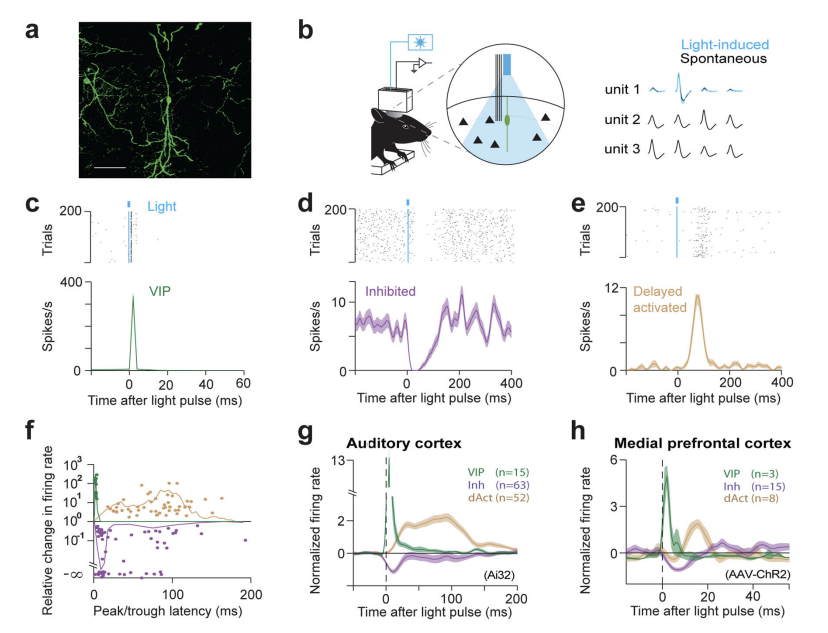

Adapted from Pi et al. (2013), Fig. 1, *Cortical interneurons that specialize in disinhibitory control*

## 3 · Feedforward networks with parallel pathways

With strictly negative local self-dynamics, feedforward coupling changes response strength and timescale without changing the eigenvalues or stability.

Here, we consider a direct path $m\to i$ and an indirect path $m\to j\to i$ first, with local decay times $\gamma_m,\gamma_j,\gamma_i$. Let $A_{im},A_{jm},A_{ij}>0$ denote coupling magnitudes; the coupling $j\to i$ is either positive or negative. Pathway gains add, and moment-based response times combine through signed gain weighting:
$$
R=R_1+R_2,
\qquad
T=\frac{R_1T_1+R_2T_2}{R_1+R_2}.
$$

For this feedforward triangle,
$$
R_{\pm}
=\gamma_m\gamma_i
\left(A_{im}\pm\gamma_j A_{ij}A_{jm}\right),
$$
$$
T_{\pm}
=\gamma_m+\gamma_i
\pm\frac{\gamma_j^2 A_{ij}A_{jm}}
{A_{im}\pm\gamma_j A_{ij}A_{jm}}.
$$

- **All-positive ($+$):** At fixed local decay times, strengthening the indirect path increases gain, while $T_+$ approaches $\gamma_m+\gamma_j+\gamma_i$.
- **Feedforward inhibition ($-$):** The paths compete through cancellation. When $A_{im}=\gamma_j A_{ij}A_{jm}$, the gain vanishes and $T_-$ is undefined, although a transient response remains. Near cancellation, $T_-$ is not a reliable measure of response timescale.

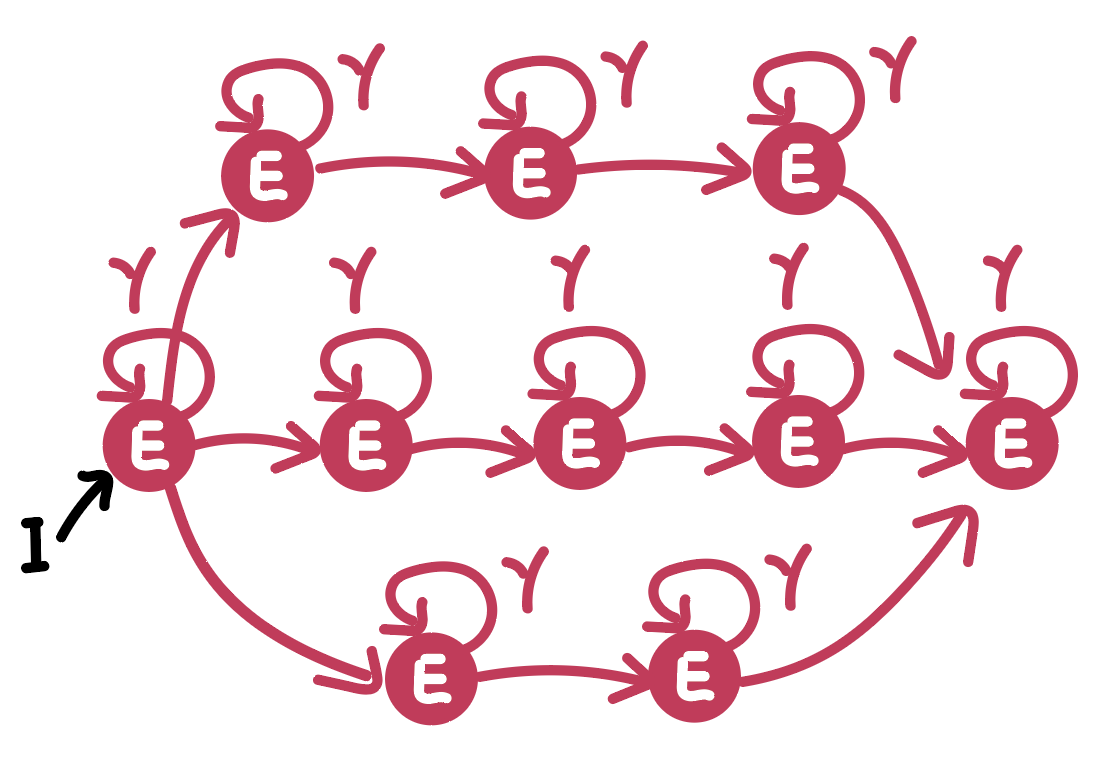

More generally, each walk $w:m\to i$ contributes a signed gain $r_w$ and a cumulative time $t_w$:
$$
r_w=\left(\prod_{e\in w}A_e\right)\left(\prod_{v\in w}\gamma_v\right),
\qquad
t_w=\sum_{v\in w}\gamma_v.
$$
The total gain and moment-based time are
$$
R_i^{(m)}=\sum_w r_w,
\qquad
\tau_i^{(m)}=\frac{\sum_w r_w t_w}{\sum_w r_w}.
$$

Node factors include both endpoints and count repeated visits. In feedforward networks, these are finite sums over directed paths. 

In [7]:
# ------------------------------------------------------------
# Fixed settings
# ------------------------------------------------------------
T_MAX = 30.0
SAMPLES = 1501
Y_LIMITS = (-7.5, 7.5)

POSITIVE = "#c34048"  # Red: positive coupling
NEGATIVE = "#2864ad"  # Blue: negative coupling
PATH1 = "#bb8b18"
PATH2 = "#7255a5"


def triangle_matrix(sign, strength, middle_tau):
    # Node order: source, middle, target.
    # Source and target local time constants are fixed at 1.
    H = -np.diag([1.0, 1.0 / middle_tau, 1.0])
    H[1, 0] = 1.0
    H[2, 0] = 1.0
    H[2, 1] = sign * strength
    return H


def triangle_response(H, kind):
    """Exact sampled response to a unit input at the source."""
    t = np.linspace(0, T_MAX, SAMPLES)
    dt = t[1] - t[0]
    b = np.array([1.0, 0.0, 0.0])
    X = np.zeros((SAMPLES, 3))

    if kind == "impulse":
        # Unit-area impulse: x(0+) = b.
        X[0] = b
        P = expm(H * dt)
        for k in range(1, SAMPLES):
            X[k] = P @ X[k - 1]

    else:
        # Unit step from rest.
        A = np.zeros((4, 4))
        A[:3, :3] = H
        A[:3, 3] = b
        P = expm(A * dt)
        y = np.array([0.0, 0.0, 0.0, 1.0])

        for k in range(1, SAMPLES):
            y = P @ y
            X[k] = y[:3]

    return t, X


def draw_triangle(ax, sign, strength, middle_tau, kind):
    positions = {
        "Source": np.array([-1.2, 0.65]),
        "Middle": np.array([0.0, -0.75]),
        "Target": np.array([1.2, 0.65]),
    }
    radius = 0.28

    def edge(start_name, end_name, value, label_position, label):
        start = positions[start_name]
        end = positions[end_name]
        direction = (end - start) / np.linalg.norm(end - start)

        color = (
            POSITIVE if value > 0
            else NEGATIVE if value < 0
            else "#999999"
        )

        ax.add_patch(FancyArrowPatch(
            start + radius * direction,
            end - radius * direction,
            arrowstyle="-|>",
            mutation_scale=23,
            linewidth=2.7,
            color=color,
            linestyle="-" if value != 0 else ":",
            zorder=2,
        ))

        ax.text(
            *label_position, label,
            ha="center", va="center",
            color=color, fontsize=14,
        )

    edge(
        "Source", "Target", 1.0,
        (0.0, 0.98), "Path 1: +1",
    )
    edge(
        "Source", "Middle", 1.0,
        (-0.9, -0.25), "+1",
    )
    edge(
        "Middle", "Target", sign * strength,
        (0.95, -0.25), f"{sign * strength:+.2f}",
    )

    for name, position in positions.items():
        ax.add_patch(Circle(
            position, radius,
            facecolor="#edf2f7",
            edgecolor="#526175",
            linewidth=1.5,
            zorder=3,
        ))
        ax.text(
            *position, name,
            ha="center", va="center",
            fontsize=12, zorder=4,
        )

    ax.text(
        0, -1.25,
        rf"Path 2 through middle: $\tau_m={middle_tau:.2f}$",
        ha="center", fontsize=14,
    )

    source = positions["Source"]
    ax.annotate(
        "",
        xy=(source[0], source[1] + radius),
        xytext=(source[0], source[1] + 0.85),
        arrowprops={
            "arrowstyle": "-|>",
            "color": "#333333",
            "lw": 2,
            "mutation_scale": 18,
        },
    )
    ax.text(
        source[0], source[1] + 0.95,
        "Unit step" if kind == "step" else r"Unit $\delta(t)$",
        ha="center", fontsize=13,
    )

    ax.set(
        title="All positive" if sign > 0 else "Inhibitory path 2",
        xlim=(-1.9, 1.9),
        ylim=(-1.55, 1.95),
    )
    ax.set_aspect("equal")
    ax.axis("off")


def triangle_comparison(strength=1.0, middle_tau=1.0, kind="step"):
    # Moment-based times, not peak times or exponential decay constants.
    #
    # T = integral(t*h(t)) / integral(h(t))
    #
    # For step responses with nonzero steady response R:
    # T = integral(1 - x_step(t)/R) dt
    #
    # Positive triangle, at fixed middle_tau:
    # T_total approaches T_indirect as strength increases.
    #
    # Inhibitory triangle:
    # T_total is undefined at strength*middle_tau = 1.

    T_direct = 2.0
    T_indirect = 2.0 + middle_tau

    with plt.rc_context({
        "figure.dpi": 110,
        "font.size": 15,
        "axes.titlesize": 20,
        "axes.labelsize": 17,
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,
        "legend.fontsize": 12,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }):
        fig, axes = plt.subplots(
            2, 2,
            figsize=(16, 10),
            gridspec_kw={"width_ratios": [1, 2]},
            layout="constrained",
        )

        for row, sign in enumerate([1, -1]):
            H = triangle_matrix(sign, strength, middle_tau)
            t, X = triangle_response(H, kind)

            # Separate the two contributions to the target response.
            H_direct = H.copy()
            H_direct[2, 1] = 0.0

            H_indirect = H.copy()
            H_indirect[2, 0] = 0.0

            _, X_direct = triangle_response(H_direct, kind)
            _, X_indirect = triangle_response(H_indirect, kind)

            draw_triangle(
                axes[row, 0], sign, strength, middle_tau, kind
            )

            # Signed impulse areas, equal to the steady step responses.
            R_direct = 1.0
            R_indirect = sign * strength * middle_tau
            R_total = R_direct + R_indirect

            if abs(R_total) > 1e-10:
                T_total = (
                    R_direct * T_direct
                    + R_indirect * T_indirect
                ) / R_total
                total_label = (
                    rf"$T_{{\mathrm{{total}}}}={T_total:.2f}$"
                )
            else:
                total_label = (
                    r"$T_{\mathrm{total}}$ undefined: cancellation"
                )

            ax = axes[row, 1]

            ax.plot(
                t, X_direct[:, 2],
                color=PATH1, lw=2.5, ls="--",
                label="Path 1: direct",
            )
            ax.plot(
                t, X_indirect[:, 2],
                color=PATH2, lw=2.5, ls="--",
                label="Path 2: through middle",
            )
            ax.plot(
                t, X[:, 2],
                color="black", lw=3,
                label="Total target response",
            )

            # Only the indirect-path time gets a vertical marker.
            if strength > 0:
                ax.axvline(
                    T_indirect,
                    color=PATH2,
                    lw=2,
                    ls=":",
                    label=rf"$T_2=2+\tau_m={T_indirect:.2f}$",
                )

                ax.text(
                    T_indirect + 0.35, 0.04,
                    rf"$T_2={T_indirect:.2f}$",
                    transform=ax.get_xaxis_transform(),
                    color=PATH2,
                    fontsize=15,
                    va="bottom",
                    bbox=dict(
                        facecolor="white",
                        edgecolor="none",
                        alpha=0.85,
                        pad=2,
                    ),
                )

            note = "Moment-based time\n" + total_label
            if strength == 0:
                note += "\nPath 2 absent"
            elif sign < 0:
                note += "\nSensitive to signed cancellation"

            ax.text(
                0.98, 0.04, note,
                transform=ax.transAxes,
                ha="right", va="bottom",
                fontsize=13,
                bbox=dict(
                    facecolor="white",
                    edgecolor="#dddddd",
                    alpha=0.9,
                    pad=5,
                ),
            )

            ax.axhline(0, color="gray", lw=0.8)
            ax.set(
                title=kind.capitalize(),
                xlabel="Time",
                ylabel="Target response",
                xlim=(0, T_MAX),
                ylim=Y_LIMITS,
            )
            ax.grid(alpha=0.18)
            ax.legend(loc="upper right")

        plt.show()


# ------------------------------------------------------------
# Interactive controls
# ------------------------------------------------------------
style = {"description_width": "initial"}

input_control = widgets.ToggleButtons(
    options=[("Step", "step"), ("Impulse (δ)", "impulse")],
    value="step",
    description="Input",
    style=style,
)

strength_control = widgets.FloatSlider(
    value=1.0, min=0.0, max=2.0, step=0.05,
    description="Middle → target magnitude",
    continuous_update=False,
    style=style,
    layout=widgets.Layout(width="520px"),
)

middle_tau_control = widgets.FloatSlider(
    value=1.0, min=0.5, max=3.0, step=0.1,
    description="Middle time constant",
    continuous_update=False,
    style=style,
    layout=widgets.Layout(width="520px"),
)

output = widgets.interactive_output(
    triangle_comparison,
    {
        "strength": strength_control,
        "middle_tau": middle_tau_control,
        "kind": input_control,
    },
)

display(widgets.VBox([
    input_control,
    strength_control,
    middle_tau_control,
    output,
]))

## 4 · Feedback loops with signed couplings

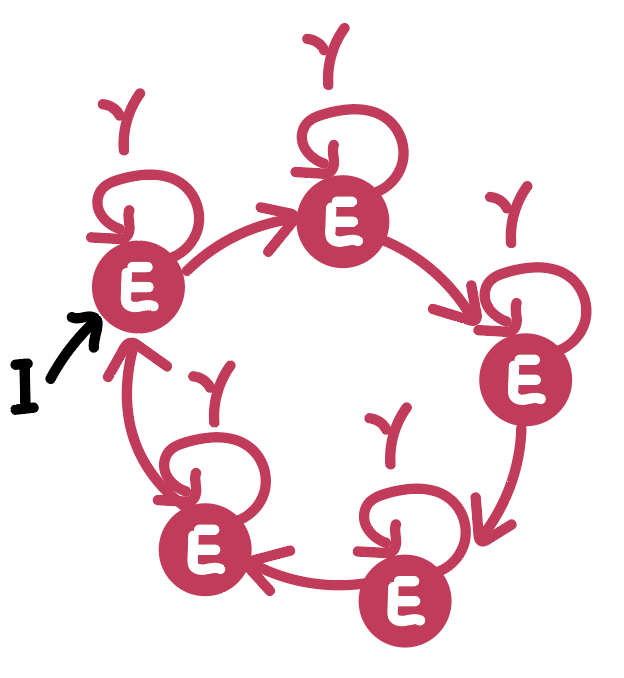

Feedback changes the eigenvalue spectrum and can produce amplification, slowing, oscillations, or instability. Stability requires $\mathrm{Re}(\lambda)<0$ for every eigenvalue; nonzero imaginary parts describe oscillatory modes.

Here, we consider a simple loop $m\to j\to i\to m$, define the signed loop gain and loop traversal time:
$$
g=\gamma_m\gamma_j\gamma_i A_{jm}A_{ij}A_{mi},
\qquad
T_{\mathrm{loop}}=\gamma_m+\gamma_j+\gamma_i.
$$

Without the return edge $i\to m$, the source-to-target gain and moment-based time of this directed chain are
$$
R_0=\gamma_m\gamma_j\gamma_i A_{jm}A_{ij},
\qquad
T_0=\gamma_m+\gamma_j+\gamma_i.
$$

Each additional circuit multiplies the walk gain by $g$ and adds $T_{\mathrm{loop}}$ to its time. Summing repeated circuits gives
$$
R=R_0\sum_{n=0}^{\infty}g^n
=\frac{R_0}{1-g}, \qquad |g|<1
$$
$$
T=
\frac{\sum_{n=0}^{\infty}g^n(T_0+nT_{\mathrm{loop}})}
{\sum_{n=0}^{\infty}g^n}
=
T_0+\frac{g}{1-g}T_{\mathrm{loop}}.
$$

For this triangle with the corresponding source and target, $T_0=T_{\mathrm{loop}}$, so $T=T_0/(1-g)$.

- **Positive feedback ($0<g<1$):** repeated circulation amplifies the gain and increases the response time; both diverge as $g\to1^-$.
- **Negative feedback ($g<0$):** successive circuits alternate in sign, reducing the signed gain and moment time. Oscillations can make this moment time a poor measure when magnitude of $g$ is too large.


In [8]:
# ------------------------------------------------------------
# Fixed settings
# ------------------------------------------------------------
T_MAX = 30.0
SAMPLES = 1501
Y_LIMITS = (-7.5, 7.5)
REAL_LIMITS = (-5.0, 3.0)
IMAG_LIMITS = (-4.0, 4.0)

POSITIVE = "#c34048"   # Red: positive coupling
NEGATIVE = "#2864ad"   # Blue: negative coupling

NODE_COLORS = ["#bb8b18", "#7255a5", "#222222"]
NODE_NAMES = ["Source", "Middle", "Target"]


def feedback_matrix(sign, strength, middle_tau):
    # Node order: source, middle, target.
    # Source → middle → target → source.
    H = -np.diag([1.0, 1.0 / middle_tau, 1.0])
    H[1, 0] = 1.0
    H[2, 1] = 1.0
    H[0, 2] = sign * strength
    return H


def feedback_response(H, kind):
    """Exact sampled response to a unit input at the source."""
    t = np.linspace(0.0, T_MAX, SAMPLES)
    dt = t[1] - t[0]
    b = np.array([1.0, 0.0, 0.0])
    X = np.zeros((SAMPLES, 3))

    if kind == "impulse":
        X[0] = b
        P = expm(H * dt)

        for k in range(1, SAMPLES):
            X[k] = P @ X[k - 1]
    else:
        A = np.zeros((4, 4))
        A[:3, :3] = H
        A[:3, 3] = b
        P = expm(A * dt)
        y = np.array([0.0, 0.0, 0.0, 1.0])

        for k in range(1, SAMPLES):
            y = P @ y
            X[k] = y[:3]

    return t, X


def draw_feedback_triangle(ax, sign, strength, middle_tau, kind):
    positions = {
        "Source": np.array([-1.2, 0.65]),
        "Middle": np.array([0.0, -0.75]),
        "Target": np.array([1.2, 0.65]),
    }
    radius = 0.28

    def edge(start_name, end_name, value, label_position, label):
        start = positions[start_name]
        end = positions[end_name]
        direction = (end - start) / np.linalg.norm(end - start)

        color = (
            POSITIVE if value > 0
            else NEGATIVE if value < 0
            else "#999999"
        )

        ax.add_patch(FancyArrowPatch(
            start + radius * direction,
            end - radius * direction,
            arrowstyle="-|>",
            mutation_scale=23,
            linewidth=2.7,
            color=color,
            linestyle="-" if value != 0 else ":",
            zorder=2,
        ))
        ax.text(
            *label_position, label,
            ha="center", va="center",
            color=color, fontsize=14,
        )

    edge("Source", "Middle", 1.0, (-0.9, -0.25), "+1")
    edge("Middle", "Target", 1.0, (0.9, -0.25), "+1")
    edge(
        "Target", "Source", sign * strength,
        (0.0, 0.98), f"Feedback: {sign * strength:+.2f}",
    )

    for j, (name, position) in enumerate(positions.items()):
        ax.add_patch(Circle(
            position, radius,
            facecolor="#edf2f7",
            edgecolor=NODE_COLORS[j],
            linewidth=2,
            zorder=3,
        ))
        ax.text(
            *position, name,
            ha="center", va="center",
            fontsize=12, zorder=4,
        )

    ax.text(
        0, -1.25,
        rf"Middle: $\tau_m={middle_tau:.2f}$",
        ha="center", fontsize=14,
    )

    source = positions["Source"]
    ax.annotate(
        "",
        xy=(source[0], source[1] + radius),
        xytext=(source[0], source[1] + 0.85),
        arrowprops={
            "arrowstyle": "-|>",
            "color": "#333333",
            "lw": 2,
            "mutation_scale": 18,
        },
    )
    ax.text(
        source[0], source[1] + 0.95,
        "Unit step" if kind == "step" else r"Unit $\delta(t)$",
        ha="center", fontsize=13,
    )

    ax.set(
        title="Positive feedback" if sign > 0 else "Negative feedback",
        xlim=(-1.9, 1.9),
        ylim=(-1.55, 1.95),
    )
    ax.set_aspect("equal")
    ax.axis("off")


def feedback_comparison(strength=0.5, middle_tau=1.0, kind="step"):
    with plt.rc_context({
        "figure.dpi": 110,
        "font.size": 14,
        "axes.titlesize": 19,
        "axes.labelsize": 16,
        "xtick.labelsize": 13,
        "ytick.labelsize": 13,
        "legend.fontsize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }):
        fig, axes = plt.subplots(
            2, 3,
            figsize=(20, 10),
            gridspec_kw={"width_ratios": [1, 1.8, 1.1]},
            layout="constrained",
        )

        # Open-chain reference, shared by both rows.
        H_open = feedback_matrix(1, 0.0, middle_tau)
        t, X_open = feedback_response(H_open, kind)

        for row, sign in enumerate([1, -1]):
            H = feedback_matrix(sign, strength, middle_tau)
            _, X = feedback_response(H, kind)

            eigenvalues = np.linalg.eigvals(H)
            alpha = np.max(eigenvalues.real)

            if alpha < -1e-9:
                status, status_color = "Stable", "#26734d"
            elif alpha > 1e-9:
                status, status_color = "Unstable", POSITIVE
            else:
                status, status_color = "Stability boundary", "#9a6d00"

            # ----------------------------------------------------
            # Left: circuit
            # ----------------------------------------------------
            draw_feedback_triangle(
                axes[row, 0], sign, strength, middle_tau, kind
            )

            # ----------------------------------------------------
            # Middle: time traces
            # ----------------------------------------------------
            ax = axes[row, 1]

            for j in range(3):
                ax.plot(
                    t, X[:, j],
                    color=NODE_COLORS[j],
                    lw=2.8 if j == 2 else 2.0,
                    label=NODE_NAMES[j],
                )

            ax.plot(
                t, X_open[:, 2],
                color="#888888", ls="--", lw=2.3,
                label="Target: open chain",
            )
            ax.axhline(0, color="gray", lw=0.8)

            # Infinite-time metrics are shown only for stable systems.
            if alpha < -1e-9:
                b = np.array([1.0, 0.0, 0.0])
                R = np.linalg.solve(-H, b)
                M1 = np.linalg.solve(-H, R)
                T_target = M1[2] / R[2]

                note = (
                    rf"$R_{{\mathrm{{target}}}}={R[2]:.2f}$"
                    "\n"
                    rf"$T_{{\mathrm{{target}}}}={T_target:.2f}$"
                    " (moment time)"
                )
            else:
                note = "No finite infinite-time response metrics"

            if np.any((X < Y_LIMITS[0]) | (X > Y_LIMITS[1])):
                note += "\nTraces exceed the fixed y-limits"

            ax.text(
                0.98, 0.04, note,
                transform=ax.transAxes,
                ha="right", va="bottom",
                fontsize=11,
                bbox=dict(
                    facecolor="white", edgecolor="#dddddd",
                    alpha=0.9, pad=5,
                ),
            )

            ax.set(
                title=kind.capitalize(),
                xlabel="Time",
                ylabel="Activity deviation",
                xlim=(0, T_MAX),
                ylim=Y_LIMITS,
            )
            ax.grid(alpha=0.18)
            ax.legend(loc="upper right", ncol=2)

            # ----------------------------------------------------
            # Right: eigenvalue spectrum
            # ----------------------------------------------------
            ax = axes[row, 2]

            ax.axvspan(
                0, REAL_LIMITS[1],
                color=POSITIVE, alpha=0.06,
            )
            ax.axvline(0, color=POSITIVE, ls="--", lw=1.4)
            ax.axhline(0, color="gray", lw=0.8)

            ax.scatter(
                eigenvalues.real, eigenvalues.imag,
                s=110, color=status_color,
                edgecolors="white", linewidths=0.8,
                zorder=3,
            )

            ax.text(
                0.05, 0.95,
                status + "\n" + rf"$\max\,\mathrm{{Re}}(\lambda)={alpha:.3f}$",
                transform=ax.transAxes,
                ha="left", va="top",
                color=status_color, fontsize=12,
            )
            ax.set(
                title="Eigenvalues",
                xlabel=r"$\mathrm{Re}(\lambda)$",
                ylabel=r"$\mathrm{Im}(\lambda)$",
                xlim=REAL_LIMITS,
                ylim=IMAG_LIMITS,
            )
            ax.set_aspect("equal", adjustable="box")
            ax.grid(alpha=0.18)

        plt.show()


# ------------------------------------------------------------
# Interactive controls
# ------------------------------------------------------------
style = {"description_width": "initial"}

input_control = widgets.ToggleButtons(
    options=[("Step", "step"), ("Impulse (δ)", "impulse")],
    value="step",
    description="Input",
    style=style,
)

strength_control = widgets.FloatSlider(
    value=0.5, min=0.0, max=10.0, step=0.05,
    description="Target → source magnitude",
    continuous_update=False,
    style=style,
    layout=widgets.Layout(width="540px"),
)

middle_tau_control = widgets.FloatSlider(
    value=1.0, min=0.5, max=3.0, step=0.1,
    description="Middle time constant",
    continuous_update=False,
    style=style,
    layout=widgets.Layout(width="540px"),
)

output = widgets.interactive_output(
    feedback_comparison,
    {
        "strength": strength_control,
        "middle_tau": middle_tau_control,
        "kind": input_control,
    },
)

display(widgets.VBox([
    input_control,
    strength_control,
    middle_tau_control,
    output,
]))

## 5 · Recurrent excitatory–inhibitory circuits
### 5A · Inhibitory stabilization and the paradoxical response

Apply a positive step input to the inhibitory population:
$$
\dot{\mathbf{x}}=H\mathbf{x}+\begin{pmatrix}0\\1\end{pmatrix},
\qquad
H=\begin{pmatrix}w-1&-g\\h&-(1+v)\end{pmatrix}.
$$

For a stable network with $g,h>0$, the steady changes are
$$
R_E=-\frac{g}{\det H}<0,
\qquad
R_I=\frac{1-w}{\det H}.
$$

**Normal response ($w<1$):** extra input increases inhibitory activity and suppresses excitatory activity. The isolated E population is stable.

**Question**: in which cases does a paradoxical response occur, and why is it called “paradoxical”?


<details>
<summary>Interpretation / discussion</summary>

**Paradoxical response ($w>1$):** extra input ultimately decreases both inhibitory and excitatory activity. The isolated E population is unstable, so inhibition is essential for network stability—an **inhibition-stabilized network (ISN)**.

**Mechanism:** I activity initially rises, suppressing E. This reduces the excitatory drive back to I. In the ISN regime, that loss outweighs the added input, leaving I below its original baseline.

**Literature anchor:** [Tsodyks et al. (1997), *Paradoxical Effects of External Modulation of Inhibitory Interneurons*](https://doi.org/10.1523/JNEUROSCI.17-11-04382.1997).
</details>

In [9]:
POSITIVE = "#c34048"
NEGATIVE = "#2864ad"

T_MAX = 30.0
Y_LIMITS = (-6.0, 3.0)


def isn_demo(excitation=1.4, inhibition=1.5):
    # dx/dt = Hx + b*u(t), with a unit step into I.
    H = np.array([
        [excitation - 1.0, -inhibition],
        [1.0,             -1.5],
    ])
    b = np.array([0.0, 1.0])

    eigenvalues = np.linalg.eigvals(H)
    alpha = np.max(eigenvalues.real)
    stable = alpha < -1e-9

    if stable:
        status, status_color = "Stable", "#26734d"
        R = np.linalg.solve(-H, b)
    elif alpha > 1e-9:
        status, status_color = "Unstable", POSITIVE
        R = None
    else:
        status, status_color = "Stability boundary", "#9a6d00"
        R = None

    # Exact finite-time step response, including unstable settings.
    t = np.linspace(0, T_MAX, 1501)
    A = np.zeros((3, 3))
    A[:2, :2] = H
    A[:2, 2] = b
    P = expm(A * (t[1] - t[0]))

    y = np.array([0.0, 0.0, 1.0])
    X = np.zeros((len(t), 2))
    for k in range(1, len(t)):
        y = P @ y
        X[k] = y[:2]

    with plt.rc_context({
        "figure.dpi": 110,
        "font.size": 14,
        "axes.titlesize": 19,
        "axes.labelsize": 16,
        "xtick.labelsize": 13,
        "ytick.labelsize": 13,
        "legend.fontsize": 12,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }):
        fig, axes = plt.subplots(
            1, 3,
            figsize=(17, 5),
            gridspec_kw={"width_ratios": [1, 1.5, 1]},
            layout="constrained",
        )

        # --------------------------------------------------------
        # Left: E–I circuit
        # --------------------------------------------------------
        ax = axes[0]
        positions = {"E": (-0.85, 0.0), "I": (0.85, 0.0)}
        radius = 0.29

        # E → I: excitation; I → E: inhibition.
        for start, end, color, weight in [
            ("E", "I", POSITIVE, 1.0),
            ("I", "E", NEGATIVE, inhibition),
        ]:
            ax.add_patch(FancyArrowPatch(
                positions[start], positions[end],
                connectionstyle="arc3,rad=0.35",
                arrowstyle="-|>",
                mutation_scale=23,
                linewidth=2.8,
                color=color if weight > 0 else "#999999",
                linestyle="-" if weight > 0 else ":",
                shrinkA=32,
                shrinkB=32,
                zorder=2,
            ))

        ax.text(
            0, -0.49, "+1",
            color=POSITIVE, ha="center", fontsize=15,
        )
        ax.text(
            0, 0.49, f"{-inhibition:+.2f}",
            color=NEGATIVE, ha="center", fontsize=15,
        )

        for name, position in positions.items():
            color = POSITIVE if name == "E" else NEGATIVE
            ax.add_patch(Circle(
                position, radius,
                facecolor="#edf2f7",
                edgecolor=color,
                linewidth=2,
                zorder=3,
            ))
            ax.text(
                *position, name,
                ha="center", va="center",
                fontsize=19, zorder=4,
            )

        ax.annotate(
            "",
            xy=(0.85, radius),
            xytext=(0.85, 1.05),
            arrowprops={
                "arrowstyle": "-|>",
                "color": "#333333",
                "lw": 2,
                "mutation_scale": 20,
            },
        )
        ax.text(
            0.85, 1.17, "Unit step",
            ha="center", fontsize=14,
        )

        ax.text(
            0, -1.05,
            rf"$H_{{EE}}=w-1={H[0, 0]:+.2f}$"
            "\n"
            r"$H_{II}=-1.5$",
            ha="center", va="center", fontsize=15,
        )
        ax.set(
            title="E–I circuit",
            xlim=(-1.55, 1.55),
            ylim=(-1.5, 1.6),
        )
        ax.set_aspect("equal")
        ax.axis("off")

        # --------------------------------------------------------
        # Middle: step responses
        # --------------------------------------------------------
        ax = axes[1]
        ax.plot(t, X[:, 0], color=POSITIVE, lw=2.5, label="E")
        ax.plot(t, X[:, 1], color=NEGATIVE, lw=2.5, label="I")
        ax.axhline(0, color="gray", lw=0.8)

        if stable:
            ax.axhline(
                R[1], color=NEGATIVE, ls="--", lw=1.5,
                label=rf"$I_{{\mathrm{{ss}}}}={R[1]:.2f}$",
            )
            paradoxical = R[1] < -1e-8
            note = (
                "Paradoxical I response"
                if paradoxical else "Non-paradoxical I response"
            )
        else:
            note = status + "\nNo attracting steady response"

        if np.any((X < Y_LIMITS[0]) | (X > Y_LIMITS[1])):
            note += "\nTraces exceed fixed y-limits"

        ax.text(
            0.97, 0.04, note,
            transform=ax.transAxes,
            ha="right", va="bottom",
            fontsize=12,
            bbox=dict(
                facecolor="white",
                edgecolor="#dddddd",
                alpha=0.9,
                pad=5,
            ),
        )
        ax.set(
            title="Step input to I",
            xlabel="Time",
            ylabel="Activity deviation",
            xlim=(0, T_MAX),
            ylim=Y_LIMITS,
        )
        ax.grid(alpha=0.18)
        ax.legend(loc="upper right")

        # --------------------------------------------------------
        # Right: eigenvalue spectrum
        # --------------------------------------------------------
        ax = axes[2]
        ax.axvspan(0, 2, color=POSITIVE, alpha=0.06)
        ax.axvline(0, color=POSITIVE, ls="--", lw=1.4)
        ax.axhline(0, color="gray", lw=0.8)

        ax.scatter(
            eigenvalues.real, eigenvalues.imag,
            s=110,
            color=status_color,
            edgecolors="white",
            zorder=3,
        )
        ax.text(
            0.05, 0.95,
            status + "\n" + rf"$\max\,\mathrm{{Re}}(\lambda)={alpha:.3f}$",
            transform=ax.transAxes,
            ha="left", va="top",
            color=status_color, fontsize=12,
        )
        ax.set(
            title="Eigenvalues",
            xlabel=r"$\mathrm{Re}(\lambda)$",
            ylabel=r"$\mathrm{Im}(\lambda)$",
            xlim=(-3, 2),
            ylim=(-2.5, 2.5),
        )
        ax.set_aspect("equal", adjustable="box")
        ax.grid(alpha=0.18)

        plt.show()


# ------------------------------------------------------------
# Interactive controls
# ------------------------------------------------------------
style = {"description_width": "initial"}

excitation_control = widgets.FloatSlider(
    value=1.4, min=0.0, max=3.0, step=0.05,
    description="Recurrent excitation w",
    continuous_update=False,
    style=style,
    layout=widgets.Layout(width="500px"),
)

inhibition_control = widgets.FloatSlider(
    value=1.5, min=0.0, max=4.0, step=0.05,
    description="Inhibitory coupling",
    continuous_update=False,
    style=style,
    layout=widgets.Layout(width="500px"),
)

output = widgets.interactive_output(
    isn_demo,
    {
        "excitation": excitation_control,
        "inhibition": inhibition_control,
    },
)

display(widgets.VBox([
    excitation_control,
    inhibition_control,
    output,
]))

### 5B · Balanced amplification: large transients with fixed eigenvalues

Consider the minimal E–I circuit
$$
H=-I+W,
\qquad
W=\begin{pmatrix}w&-w\\w&-w\end{pmatrix},
\qquad w\geq0.
$$
Excitation and inhibition cancel when $x_E=x_I$. Since $W^2=0$,
$$
\lambda_1=\lambda_2=-1,
\qquad
e^{Ht}=e^{-t}(I+tW).
$$
Every perturbation eventually decays, but the term $tW$ can produce **transient amplification**.

**Mechanism:** coupling between population patterns. Define orthonormal common and difference coordinates:
$$
q=\frac{x_E+x_I}{\sqrt2},
\qquad
d=\frac{x_E-x_I}{\sqrt2}.
$$
Then
$$
\begin{pmatrix}\dot q\\\dot d\end{pmatrix}
=
\begin{pmatrix}-1&2w\\0&-1\end{pmatrix}
\begin{pmatrix}q\\d\end{pmatrix},
$$
so
$$
d(t)=d_0e^{-t},
\qquad
q(t)=e^{-t}(q_0+2wt\,d_0).
$$
The difference pattern drives the common pattern, creating **feedforward amplification between activity patterns within a recurrent circuit**. A pure common-pattern perturbation simply decays; a difference-pattern perturbation can drive a large common response.

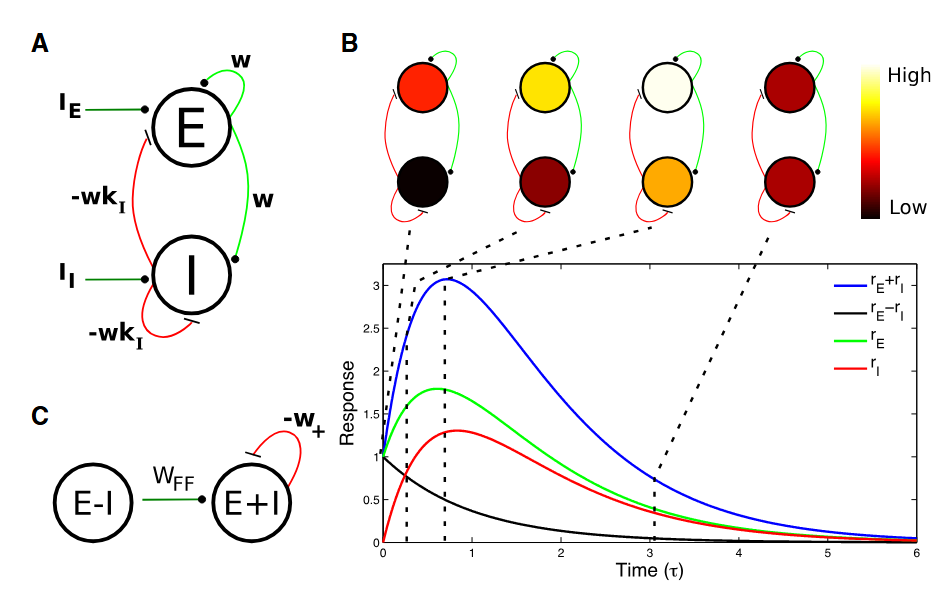

Murphy & Miller (2009), Fig. 1, *Balanced Amplification: A New Mechanism of Selective Amplification of Neural Activity Patterns*.


**Relation to normal matrices.** A real matrix is normal if
$$
HH^T=H^TH.
$$
A stable normal matrix cannot amplify the Euclidean norm of an unforced perturbation:
$$
\|e^{Ht}\|_2=e^{t\max_j\operatorname{Re}\lambda_j}<1,
\qquad t>0.
$$
Here, $H$ is **non-normal** for $w>0$. Its population patterns are coupled, so eigenvalues alone do not determine transient amplification. The common/difference transformation gives a **real Schur form**: an orthogonal change of coordinates exposing this coupling.

Actual norm growth requires
$$
\lambda_{\max}\!\left(\frac{H+H^T}{2}\right)=w-1>0.
$$
Thus, **non-normality occurs for $w>0$, but transient norm amplification requires $w>1$**. Its magnitude depends on the perturbation direction.

**Literature anchor:** [Murphy & Miller (2009), *Balanced Amplification: A New Mechanism of Selective Amplification of Neural Activity Patterns*](https://doi.org/10.1016/j.neuron.2009.02.005).

In [10]:
RED = "#c34048"
BLUE = "#2864ad"
GOLD = "#bb8b18"
PURPLE = "#7255a5"

T_MAX = 10.0
SAMPLES = 1501


def balanced_demo(coupling=3.0, angle=-45.0):
    """
    Unit impulse with direction b = (cos(angle), sin(angle)).

    H = -I + W,  W² = 0.
    Exact response: x(t) = exp(-t) * (b + t*Wb).
    Normal reference: H_normal = -I.
    """
    w = coupling
    W = np.array([[w, -w], [w, -w]])
    H = -np.eye(2) + W

    theta = np.deg2rad(angle)
    b = np.array([np.cos(theta), np.sin(theta)])
    t = np.linspace(0.0, T_MAX, SAMPLES)

    # Exact impulse responses.
    X = np.exp(-t[:, None]) * (b + t[:, None] * (W @ b))
    X_normal = np.exp(-t[:, None]) * b

    # Orthonormal common/difference coordinates.
    q = (X[:, 0] + X[:, 1]) / np.sqrt(2)
    d = (X[:, 0] - X[:, 1]) / np.sqrt(2)

    gain = np.linalg.norm(X, axis=1)
    normal_gain = np.exp(-t)

    # Largest singular value of exp(Ht):
    # maximum response norm over unit initial conditions at each time.
    a = w * t
    envelope = np.exp(-t) * (np.sqrt(1.0 + a**2) + a)

    # Maximum instantaneous logarithmic norm-growth rate.
    max_growth = np.linalg.eigvalsh((H + H.T) / 2).max()
    initial_growth = b @ ((H + H.T) / 2) @ b

    with plt.rc_context({
        "figure.dpi": 110,
        "font.size": 15,
        "axes.titlesize": 19,
        "axes.labelsize": 16,
        "xtick.labelsize": 13,
        "ytick.labelsize": 13,
        "legend.fontsize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }):
        fig, axes = plt.subplots(
            2, 2, figsize=(15, 10), layout="constrained"
        )

        fig.suptitle(
            rf"$w={w:.2f}$"
            rf"    $\lambda_1=\lambda_2=-1$"
            rf"    $\lambda_{{\max}}((H+H^T)/2)={max_growth:.2f}$",
            fontsize=20,
        )

        # --------------------------------------------------------
        # 1. E and I responses
        # --------------------------------------------------------
        ax = axes[0, 0]
        ax.plot(t, X[:, 0], color=RED, lw=2.5, label="E")
        ax.plot(t, X[:, 1], color=BLUE, lw=2.5, label="I")
        ax.plot(
            t, X_normal[:, 0], color=RED, ls=":", lw=1.8,
            label="E: normal reference",
        )
        ax.plot(
            t, X_normal[:, 1], color=BLUE, ls=":", lw=1.8,
            label="I: normal reference",
        )
        ax.axhline(0, color="gray", lw=0.8)
        ax.set(
            title="Impulse",
            xlabel="Time",
            ylabel="Activity deviation",
            xlim=(0, T_MAX),
            ylim=(-4, 4),
        )
        ax.legend(ncol=2)

        # --------------------------------------------------------
        # 2. Feedforward interaction between population patterns
        # --------------------------------------------------------
        ax = axes[0, 1]
        ax.plot(t, q, color=PURPLE, lw=2.5, label="Common q")
        ax.plot(t, d, color=GOLD, lw=2.5, label="Difference d")
        ax.axhline(0, color="gray", lw=0.8)
        ax.text(
            0.97, 0.05,
            r"$\dot q=-q+2wd$" "\n" r"$\dot d=-d$",
            transform=ax.transAxes,
            ha="right", va="bottom",
            fontsize=17,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.9),
        )
        ax.set(
            title="Common and difference patterns",
            xlabel="Time",
            ylabel="Pattern coordinate",
            xlim=(0, T_MAX),
            ylim=(-5, 5),
        )
        ax.legend()

        # --------------------------------------------------------
        # 3. Norm gain and normal reference
        # --------------------------------------------------------
        ax = axes[1, 0]
        ax.plot(
            t, gain, color="black", lw=2.5,
            label="Chosen input",
        )
        ax.plot(
            t, envelope, color=PURPLE, ls="--", lw=2.3,
            label="Maximum over unit inputs at each time",
        )
        ax.plot(
            t, normal_gain, color="#888888", ls=":", lw=2.3,
            label=r"Normal reference: $H=-I$",
        )
        ax.axhline(1, color="gray", lw=0.9)

        peak_index = np.argmax(gain)
        ax.scatter(
            t[peak_index], gain[peak_index],
            color=GOLD, s=60, zorder=4,
        )
        ax.set(
            title="Transient gain",
            xlabel="Time",
            ylabel=r"$\|\mathbf{x}(t)\|_2/\|\mathbf{x}(0^+)\|_2$",
            xlim=(0, T_MAX),
            ylim=(0, 5),
        )
        ax.legend(loc="upper right")

        # --------------------------------------------------------
        # 4. Trajectory and population-pattern directions
        # --------------------------------------------------------
        ax = axes[1, 1]
        extent = np.array([-4.0, 4.0])

        ax.plot(
            extent, extent, color=PURPLE, ls=":", alpha=0.6,
            label="Common direction",
        )
        ax.plot(
            extent, -extent, color=GOLD, ls=":", alpha=0.6,
            label="Difference direction",
        )
        ax.plot(
            X_normal[:, 0], X_normal[:, 1],
            color="#888888", ls="--", lw=2,
            label="Normal reference",
        )
        ax.plot(
            X[:, 0], X[:, 1],
            color="black", lw=2.5, label="E–I trajectory",
        )

        # Unit circle: excursions outside it indicate norm amplification.
        phi = np.linspace(0, 2 * np.pi, 300)
        ax.plot(
            np.cos(phi), np.sin(phi),
            color="#bbbbbb", lw=1, label="Unit norm",
        )

        ax.scatter(
            b[0], b[1], color=GOLD, s=75,
            edgecolors="black", zorder=5, label="Initial",
        )
        ax.scatter(
            0, 0, color="black", s=35, zorder=5,
        )
        ax.set(
            title="Trajectory",
            xlabel="E deviation",
            ylabel="I deviation",
            xlim=(-4, 4),
            ylim=(-4, 4),
        )
        ax.set_aspect("equal", adjustable="box")
        ax.legend(loc="upper left", fontsize=10)

        for ax in axes.flat:
            ax.grid(alpha=0.15)

        plt.show()

    if np.isclose(w, 0):
        regime = "Normal: every input decays monotonically in norm."
    elif w <= 1:
        regime = "Non-normal, but no input exhibits norm growth."
    else:
        regime = "Non-normal: some input directions exhibit norm growth."

    print(regime)
    print(
        f"Chosen input: initial norm-growth rate = {initial_growth:.3f}; "
        f"sampled peak gain = {gain[peak_index]:.3f} "
        f"at t = {t[peak_index]:.3f}."
    )


# ------------------------------------------------------------
# Interactive controls
# ------------------------------------------------------------
style = {"description_width": "initial"}

coupling_control = widgets.FloatSlider(
    value=3.0, min=0.0, max=6.0, step=0.1,
    description="Coupling w",
    continuous_update=False,
    style=style,
    layout=widgets.Layout(width="500px"),
)

angle_control = widgets.FloatSlider(
    value=-45.0, min=-180.0, max=180.0, step=1.0,
    description="Input angle (degrees)",
    continuous_update=False,
    style=style,
    layout=widgets.Layout(width="500px"),
)

common_button = widgets.Button(description="Common input: E = I")
difference_button = widgets.Button(description="Difference input: E = −I")

common_button.on_click(lambda _: setattr(angle_control, "value", 45.0))
difference_button.on_click(lambda _: setattr(angle_control, "value", -45.0))

output = widgets.interactive_output(
    balanced_demo,
    {
        "coupling": coupling_control,
        "angle": angle_control,
    },
)

display(widgets.VBox([
    coupling_control,
    angle_control,
    widgets.HBox([common_button, difference_button]),
    output,
]))

### 5C · Balanced amplification in feedforward Wilson–Cowan motifs

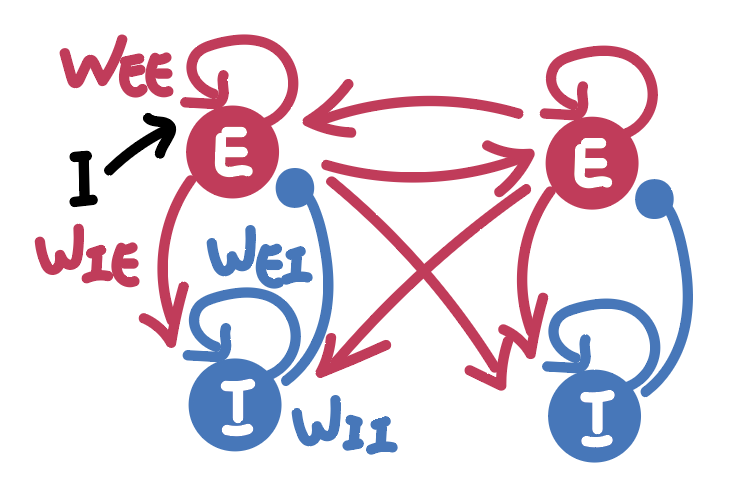

\begin{equation}
\begin{aligned}
\tau_E^i\frac{d {x}_E^i}{d t}
&=
-x_E^i
+
\sum_{j=1}^{N} w_{EE}^{ij}x_E^j
-
\sum_{j=1}^{N} w_{EI}^{ij}x_I^j
+\tau_E^iI_E^i(t),
\\
\tau_I^i\frac{d {x}_I^i}{d t}
&=
-x_I^i
+
\sum_{j=1}^{N} w_{IE}^{ij}x_E^j
-
\sum_{j=1}^{N} w_{II}^{ij}x_I^j
+ \tau_I^iI_I^i(t),
\end{aligned}
\end{equation}

Next consider two local E–I circuits, connected through $E_m\to E_i$ and $E_m\to I_i$. Each region has a local negative-feedback loop, with no E–E or I–I recurrence. Its effective gain and moment-based time are
$$
g_a=w_{EI}^{a}w_{IE}^{a},
\qquad
R_a=\frac{\tau_E^a}{1+g_a},
\qquad
T_a=\frac{\tau_E^a-g_a\tau_I^a}{1+g_a},
\quad a\in\{m,i\}.
$$

Define the direct excitatory and effective inhibitory strengths:
$$
a_E=w_{EE}^{im},
\qquad
a_I=w_{EI}^{i}w_{IE}^{im}.
$$
For input to $E_m$ and readout from $E_i$,
$$
R_{im}=\frac{a_E-a_I}{\tau_E^i}R_iR_m,
\qquad
T_{im}=T_m+T_i-\frac{a_I\tau_I^i}{a_E-a_I}.
$$

- **Excitation dominates ($a_E>a_I$):** the steady response is positive.
- **Exact balance ($a_E=a_I$):** the steady response vanishes, but delayed inhibition permits a transient response to a step input. Here $T_{im}$ is undefined; use peak amplitude and peak time.
- **Inhibition dominates ($a_E<a_I$):** the steady response is negative.

**Amplification without slowing.** Scale both feedforward projections by the same factor $c>0$, keeping the local circuits fixed:
$$
(a_E,a_I)\mapsto(ca_E,ca_I)
\quad\Longrightarrow\quad
x_E^i(t)\mapsto c\,x_E^i(t).
$$
The target response scales in amplitude without changing its shape or time.

In [11]:
# ------------------------------------------------------------
# Fixed local circuits and plotting settings
# ------------------------------------------------------------
TAU_E = 1.0
TAU_I = 0.2
W_EI = 1.0
W_IE = 0.5

RATIOS = [2.0, 1.0, 0.5]
CASE_NAMES = [
    r"Excitation dominates: $a_E/a_I=2$",
    r"Balanced: $a_E/a_I=1$",
    r"Inhibition dominates: $a_E/a_I=0.5$",
]

T_MAX = 8.0
SAMPLES = 1601
Y_LIMITS = (-3.0, 3.0)

RED = "#c34048"
BLUE = "#2864ad"
GOLD = "#bb8b18"

H_LOCAL = np.array([
    [-1.0 / TAU_E, -W_EI / TAU_E],
    [W_IE / TAU_I, -1.0 / TAU_I],
])


def wc_matrix(w_ee, ratio):
    """State order: E_m, I_m, E_i, I_i."""
    w_ie_ff = w_ee / (ratio * W_EI)

    H = np.zeros((4, 4))
    H[:2, :2] = H_LOCAL
    H[2:, 2:] = H_LOCAL
    H[2, 0] = w_ee / TAU_E
    H[3, 0] = w_ie_ff / TAU_I

    return H, w_ie_ff


def wc_step_response(H):
    """Exact sampled response to a unit step into E_m, from rest."""
    t = np.linspace(0.0, T_MAX, SAMPLES)
    b = np.array([1.0, 0.0, 0.0, 0.0])

    A = np.zeros((5, 5))
    A[:4, :4] = H
    A[:4, 4] = b
    P = expm(A * (t[1] - t[0]))

    y = np.r_[np.zeros(4), 1.0]
    X = np.zeros((SAMPLES, 4))

    for k in range(1, SAMPLES):
        y = P @ y
        X[k] = y[:4]

    return t, X


def first_crossing(t, values, threshold):
    """First threshold crossing, with linear interpolation."""
    delta = values - threshold

    for k in range(len(t) - 1):
        if delta[k] == 0:
            return t[k]
        if delta[k] * delta[k + 1] <= 0:
            fraction = -delta[k] / (delta[k + 1] - delta[k])
            return t[k] + fraction * (t[k + 1] - t[k])

    return np.nan


def draw_wc_motif(ax, w_ee, w_ie_ff, title):
    positions = {
        "Em": (-1.1, 0.7),
        "Im": (-1.1, -0.7),
        "Ei": (1.1, 0.7),
        "Ii": (1.1, -0.7),
    }
    labels = {
        "Em": r"$E_m$", "Im": r"$I_m$",
        "Ei": r"$E_i$", "Ii": r"$I_i$",
    }

    def arrow(start, end, color, curve=0.0):
        ax.add_patch(FancyArrowPatch(
            positions[start], positions[end],
            connectionstyle=f"arc3,rad={curve}",
            arrowstyle="-|>",
            mutation_scale=20,
            linewidth=2.2,
            color=color,
            shrinkA=23,
            shrinkB=23,
            zorder=2,
        ))

    for e, i in [("Em", "Im"), ("Ei", "Ii")]:
        arrow(e, i, RED, 0.3)
        arrow(i, e, BLUE, 0.3)

    arrow("Em", "Ei", RED)
    arrow("Em", "Ii", RED)

    ax.text(
        0, 0.99, rf"$w_{{EE}}^{{im}}={w_ee:.2f}$",
        ha="center", color=RED, fontsize=13,
    )
    ax.text(
        0.15, -0.36, rf"$w_{{IE}}^{{im}}={w_ie_ff:.2f}$",
        ha="center", color=RED, fontsize=13,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.85),
    )

    for name, position in positions.items():
        ax.add_patch(Circle(
            position, 0.23,
            facecolor="#edf2f7",
            edgecolor=RED if name.startswith("E") else BLUE,
            linewidth=1.8,
            zorder=3,
        ))
        ax.text(
            *position, labels[name],
            ha="center", va="center",
            fontsize=16, zorder=4,
        )

    ax.annotate(
        "",
        xy=(-1.1, 0.93),
        xytext=(-1.1, 1.4),
        arrowprops=dict(
            arrowstyle="-|>", color="#333333",
            lw=1.8, mutation_scale=18,
        ),
    )
    ax.text(-1.1, 1.48, "Unit step", ha="center", fontsize=12)
    ax.text(
        0, -1.25,
        rf"Local $w_{{EI}}={W_EI}$, $w_{{IE}}={W_IE}$",
        ha="center", fontsize=12,
    )

    ax.set(
        title=title,
        xlim=(-1.8, 1.8),
        ylim=(-1.5, 1.85),
    )
    ax.set_aspect("equal")
    ax.axis("off")


def wc_feedforward_demo(w_ee=1.0):
    with plt.rc_context({
        "figure.dpi": 110,
        "font.size": 14,
        "axes.titlesize": 17,
        "axes.labelsize": 15,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "legend.fontsize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }):
        fig, axes = plt.subplots(
            3, 3,
            figsize=(19, 13),
            gridspec_kw={"width_ratios": [1.2, 1.8, 1]},
            layout="constrained",
        )

        for row, (ratio, name) in enumerate(zip(RATIOS, CASE_NAMES)):
            H, w_ie_ff = wc_matrix(w_ee, ratio)
            H_ref, _ = wc_matrix(1.0, ratio)

            t, X = wc_step_response(H)
            _, X_ref = wc_step_response(H_ref)
            target = X[:, 2]

            b = np.array([1.0, 0.0, 0.0, 0.0])
            R = np.linalg.solve(-H, b)
            M1 = np.linalg.solve(-H, R)
            steady = 0.0 if row == 1 else R[2]

            # Left: circuit.
            draw_wc_motif(axes[row, 0], w_ee, w_ie_ff, name)

            # Middle: target response.
            ax = axes[row, 1]
            ax.plot(
                t, X_ref[:, 2],
                color="#888888", ls="--", lw=2,
                label=r"Reference: $w_{EE}^{im}=1$",
            )
            ax.plot(
                t, target, color=RED, lw=2.7,
                label=r"Target $E_i$",
            )
            ax.axhline(0, color="gray", lw=0.8)
            ax.axhline(
                steady, color=BLUE, ls=":", lw=1.5,
                label=rf"$x_{{E,\mathrm{{ss}}}}^i={steady:.2f}$",
            )

            # Select a timing measure for each case.
            if row == 0:
                # Original moment-based definition.
                marker_time = M1[2] / R[2]
                marker_y = np.interp(marker_time, t, target)
                marker_label = rf"$T={marker_time:.2f}$ s"
                timing_note = "Moment-based time"

            elif row == 1:
                # Step-response peak time.
                peak_index = np.argmax(target)
                marker_time = t[peak_index]
                marker_y = target[peak_index]
                marker_label = rf"$t_{{\mathrm{{peak}}}}={marker_time:.2f}$ s"
                timing_note = "Peak time"

            else:
                # Signed threshold relative to the FINAL steady response.
                # This is negative when inhibition dominates.
                threshold = (1.0 - np.exp(-1.0)) * steady
                marker_time = first_crossing(t, target, threshold)
                marker_y = threshold
                marker_label = rf"$t_{{63}}={marker_time:.2f}$ s"
                timing_note = "63.2% of final steady response"

                ax.axhline(
                    threshold, color=GOLD, ls=":", lw=1.5,
                    label=r"$(1-e^{-1})x_{E,\mathrm{ss}}^i$",
                )

            if np.isfinite(marker_time) and 0 <= marker_time <= T_MAX:
                ax.axvline(
                    marker_time, color=GOLD, ls="--", lw=2,
                    label=marker_label,
                )
                ax.scatter(
                    marker_time, marker_y,
                    color=GOLD, s=55, zorder=5,
                )
            else:
                timing_note += "\nOutside displayed interval"

            ax.text(
                0.98, 0.04, timing_note,
                transform=ax.transAxes,
                ha="right", va="bottom",
                fontsize=11,
                bbox=dict(
                    facecolor="white", edgecolor="#dddddd",
                    alpha=0.9, pad=4,
                ),
            )
            ax.set(
                title="Step",
                xlabel="Time (s)",
                ylabel=r"Target response $x_E^i$",
                xlim=(0, T_MAX),
                ylim=Y_LIMITS,
            )
            ax.grid(alpha=0.16)
            ax.legend(loc="upper right")

            # Right: fixed eigenvalue spectrum.
            eigenvalues = np.linalg.eigvals(H_LOCAL)
            ax = axes[row, 2]

            ax.axvline(0, color=RED, ls="--", lw=1.3)
            ax.axhline(0, color="gray", lw=0.8)
            ax.scatter(
                eigenvalues.real, eigenvalues.imag,
                s=110, color=BLUE, zorder=3,
            )
            for z in eigenvalues:
                ax.annotate(
                    "×2", (z.real, z.imag),
                    xytext=(0, 12), textcoords="offset points",
                    ha="center", fontsize=12,
                )

            ax.text(
                0.5, 0.08,
                "Fixed spectrum\nStable in all three cases",
                transform=ax.transAxes,
                ha="center", fontsize=12,
            )
            ax.set(
                title="Eigenvalues",
                xlabel=r"$\mathrm{Re}(\lambda)$",
                ylabel=r"$\mathrm{Im}(\lambda)$",
                xlim=(-6, 0.5),
                ylim=(-2.5, 2.5),
            )
            ax.set_aspect("equal", adjustable="box")
            ax.grid(alpha=0.16)

        plt.show()


# ------------------------------------------------------------
# Interactive control: fixed effective ratio within each row
# ------------------------------------------------------------
strength_control = widgets.FloatSlider(
    value=1.0, min=0.1, max=5.0, step=0.1,
    description="Feedforward w_EE",
    continuous_update=False,
    style={"description_width": "initial"},
    layout=widgets.Layout(width="520px"),
)

output = widgets.interactive_output(
    wc_feedforward_demo,
    {"w_ee": strength_control},
)

display(widgets.VBox([
    widgets.HTML(
        "<b>Unit step into E<sub>m</sub>.</b> "
        "Both feedforward weights scale together; "
        "a<sub>E</sub>/a<sub>I</sub> stays fixed within each row."
    ),
    strength_control,
    output,
]))

### References and further reading

#### 1. Integration and persistent activity
*How can recurrent interactions maintain information?*

- Seung, H. S. (1996). How the brain keeps the eyes still. *PNAS, 93*, 13339–13344. [Article](https://doi.org/10.1073/pnas.93.23.13339)  
  **Classical foundation:** recurrent integration and persistent activity.

- Mejías, J. F., & Wang, X.-J. (2022). Mechanisms of distributed working memory in a large-scale network of macaque neocortex. *eLife, 11*, e72136. [Article](https://doi.org/10.7554/eLife.72136)  
  **Further reading:** persistent activity supported by interactions between brain regions.

#### 2. Feedforward propagation and transient memory
*How can a network retain information without recurrent feedback?*

- Goldman, M. S. (2009). Memory without feedback in a neural network. *Neuron, 61*, 621–634. [Article](https://doi.org/10.1016/j.neuron.2008.12.012)  
  **Classical foundation:** feedforward propagation and memory through sequential activity.

#### 3. Inhibition, disinhibition, and pathway competition
*How do signed pathways shape signal transmission?*

- Pouille, F., & Scanziani, M. (2001). Enforcement of temporal fidelity in pyramidal cells by somatic feed-forward inhibition. *Science, 293*, 1159–1163. [Article](https://doi.org/10.1126/science.1060342)  
  **Feedforward inhibition:** restricting the temporal window for excitation.

- Pi, H.-J., et al. (2013). Cortical interneurons that specialize in disinhibitory control. *Nature, 503*, 521–524. [Article](https://doi.org/10.1038/nature12676)  
  **Disinhibition:** inhibitory populations can increase downstream activity by suppressing other inhibitory neurons.

- Reimann, M. W., Egas Santander, D., Ecker, A., & Muller, E. B. (2024). Specific inhibition and disinhibition in the higher-order structure of a cortical connectome. *Cerebral Cortex, 34*, bhae433. [Article](https://doi.org/10.1093/cercor/bhae433)  
  **Structural extension:** inhibition and disinhibition organized around higher-order connectivity motifs.

#### 4. E–I population dynamics and feedback
*How do excitatory and inhibitory populations generate collective dynamics?*

- Wilson, H. R., & Cowan, J. D. (1972). Excitatory and inhibitory interactions in localized populations of model neurons. *Biophysical Journal, 12*, 1–24. [Article](https://doi.org/10.1016/S0006-3495%2872%2986068-5)  
  **Model foundation:** coupled population dynamics, stability, and oscillations.

#### 5. Inhibitory stabilization and paradoxical responses
*Why can stimulating inhibition ultimately reduce inhibitory activity?*

- Tsodyks, M. V., Skaggs, W. E., Sejnowski, T. J., & McNaughton, B. L. (1997). Paradoxical effects of external modulation of inhibitory interneurons. *Journal of Neuroscience, 17*, 4382–4388. [Article](https://doi.org/10.1523/JNEUROSCI.17-11-04382.1997)  
  **Classical theory:** the paradoxical response in inhibition-stabilized networks.

- Sanzeni, A., et al. (2020). Inhibition stabilization is a widespread property of cortical networks. *eLife, 9*, e54875. [Article](https://doi.org/10.7554/eLife.54875)  
  **Experimental evidence:** testing inhibitory stabilization through cortical perturbations.

- Sadeh, S., & Clopath, C. (2021). Inhibitory stabilization and cortical computation. *Nature Reviews Neuroscience, 22*, 21–37. [Review](https://doi.org/10.1038/s41583-020-00390-z)  
  **Overview:** mechanisms, experimental evidence, and computational implications.

#### 6. Non-normal dynamics and transient amplification
*How can stable networks amplify activity without slow eigenvalues?*

- Murphy, B. K., & Miller, K. D. (2009). Balanced amplification: A new mechanism of selective amplification of neural activity patterns. *Neuron, 61*, 635–648. [Article](https://doi.org/10.1016/j.neuron.2009.02.005)  
  **Classical mechanism:** selective amplification through coupling between E–I population patterns.

- Bondanelli, G., & Ostojic, S. (2020). Coding with transient trajectories in recurrent neural networks. *PLOS Computational Biology, 16*, e1007655. [Article](https://doi.org/10.1371/journal.pcbi.1007655)  
  **Further reading:** non-normal amplification and stimulus coding through transient trajectories.

#### 7. Signal propagation and timescale hierarchy in cortical networks
*How do cortical connectivity and local E–I dynamics shape signal transmission and temporal integration?*

- Chaudhuri, R., Knoblauch, K., Gariel, M.-A., Kennedy, H., & Wang, X.-J. (2015). A large-scale circuit mechanism for hierarchical dynamical processing in the primate cortex. *Neuron, 88*, 419–431. [Article](https://doi.org/10.1016/j.neuron.2015.09.008)  
  **Timescale hierarchy:** local recurrent excitation and inter-area connectivity generate different integration times across cortical regions.

- Joglekar, M. R., Mejias, J. F., Yang, G. R., & Wang, X.-J. (2018). Inter-areal balanced amplification enhances signal propagation in a large-scale circuit model of the primate cortex. *Neuron, 98*, 222–234.e8. [Article](https://doi.org/10.1016/j.neuron.2018.02.031)  
  **Reliable propagation:** balanced amplification supports signal transmission across cortical areas while maintaining stability.

- Li, G., Li, S., & Wang, X.-J. (2025). A hierarchy of time constants and reliable signal propagation in the marmoset cerebral cortex. *Nature Communications, 16*, 11640. [Article](https://doi.org/10.1038/s41467-025-66699-4)  
  **Integration and propagation:** a connectome-based model links local timescale diversity with reliable inter-area transmission near criticality.

- Zeraati, R., Levina, A., Macke, J. H., & Gao, R. (2026). Neural timescales from a computational perspective. *Nature Neuroscience, 29*, 1534–1547. [Article](https://doi.org/10.1038/s41593-026-02343-8)  
  **Measurement, mechanisms, and function:** A review connecting methods for estimating neural timescales with their biophysical origins and computational roles.